# EDA: departure delays at JFK, 2025

This notebook explores the four 2025 JFK datasets in `src/datasets/` and tests which signals relate to departure delays.

- **Label:** a flight is *delayed* when `DepDel15 == 1` (departure 15+ minutes after schedule, the BTS standard). Cancelled and diverted flights are excluded from delay rates.
- **Joins:** all sources are joined on the UTC hour.
- **Synthetic data:** the FAA ASPM file is **synthetic** (`is_synthetic == True`). Its relationships to delays were built into the generator and are not real findings.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

DATA = Path("../datasets")
NY = "America/New_York"
pd.set_option("display.max_columns", 120)
pd.set_option("display.max_rows", 150)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid", context="notebook")
BLUE, GREY = "#4C72B0", "#8c8c8c"


def wilson(k, n, z=1.96):
    k, n = np.asarray(k, float), np.asarray(n, float)
    p = k / n
    d = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return c - h, c + h


def rate_by(df, cols, min_n=0):
    g = df.groupby(cols, observed=True)["delayed"].agg(flights="size", delayed="sum")
    g["rate_pct"] = 100 * g["delayed"] / g["flights"]
    return g[g["flights"] >= min_n]


def bar_rate(tab, title, ax=None, rotate=0):
    ax = ax or plt.subplots(figsize=(11, 3.8))[1]
    labels = tab.index.astype(str)
    ax.bar(labels, tab["rate_pct"], color=BLUE)
    ax.axhline(OVERALL, color=GREY, ls="--", lw=1)
    for x, (r, n) in enumerate(zip(tab["rate_pct"], tab["flights"])):
        ax.text(x, r + 0.4, f"{n:,}", ha="center", va="bottom", fontsize=7, color="#444")
    ax.set_ylabel("% delayed")
    ax.set_title(f"{title}\n(labels = flights; dashed = overall {OVERALL:.1f}%)", fontsize=10)
    ax.set_ylim(0, tab["rate_pct"].max() * 1.15)
    ax.grid(axis="x", visible=False)
    ax.tick_params(axis="x", rotation=rotate)
    return ax


def block(hour):
    return np.select(
        [(hour >= 5) & (hour < 9), (hour >= 9) & (hour < 14), (hour >= 14) & (hour < 18), (hour >= 18) & (hour < 22)],
        ["05-08", "09-13", "14-17", "18-21"], "22-04")


BLOCKS = ["05-08", "09-13", "14-17", "18-21", "22-04"]

## 1. Load and overview

Each file is loaded and its time columns parsed as timezone-aware datetimes. The IEM file's `valid` column is local time without an offset, so its UTC time is rebuilt from the `DDHHMMZ` stamp in each METAR report. That also separates the repeated 01:00 hour on 2025-11-02.

In [2]:
flights = pd.read_csv(DATA / "bts_flights_jfk_2025.csv", low_memory=False)
flights["sched_dep_utc"] = pd.to_datetime(flights["sched_dep_utc"], utc=True)
flights["dep_local"] = flights["sched_dep_utc"].dt.tz_convert(NY)

fc = pd.read_csv(DATA / "openmeteo_forecast_jfk_2025.csv")
fc["time_utc"] = pd.to_datetime(fc["time_utc"], utc=True)
fc["time_local"] = pd.to_datetime(fc["time_local"], utc=True).dt.tz_convert(NY)

aspm = pd.read_csv(DATA / "faa_aspm_jfk_2025.csv")
aspm["hour_utc"] = pd.to_datetime(aspm["hour_utc"], utc=True)
aspm["hour_local"] = pd.to_datetime(aspm["hour_local"], utc=True).dt.tz_convert(NY)

aircraft = pd.read_csv(DATA / "aircraft_capacity_jfk_2025.csv")

iem = pd.read_csv(DATA / "iem_weather_jfk_2025.csv", low_memory=False)
local_naive = pd.to_datetime(iem["valid"])
stamp = iem["metar"].str.extract(r"^\S+\s+(\d{2})(\d{2})(\d{2})Z").astype(float)
day0 = local_naive.dt.normalize()
day1 = day0 + pd.Timedelta(days=1)
utc_day = day0.where(stamp[0] == local_naive.dt.day, day1.where(stamp[0] == day1.dt.day))
utc = utc_day + pd.to_timedelta(stamp[1], unit="h") + pd.to_timedelta(stamp[2], unit="m")
offset_h = (utc - local_naive).dt.total_seconds() / 3600
from_metar = offset_h.isin([4, 5])
fallback = local_naive.dt.tz_localize(NY, ambiguous="NaT", nonexistent="NaT").dt.tz_convert("UTC").dt.tz_localize(None)
iem["valid_utc"] = utc.where(from_metar, fallback).dt.tz_localize("UTC")
iem["valid_local"] = iem["valid_utc"].dt.tz_convert(NY)
iem["metar_minute"] = stamp[2]
print(f"IEM UTC from METAR stamp: {from_metar.sum():,} rows; from tz rules: {(~from_metar & iem.valid_utc.notna()).sum():,}; "
      f"unresolved: {iem.valid_utc.isna().sum():,}")

IEM UTC from METAR stamp: 112,733 rows; from tz rules: 0; unresolved: 0


In [3]:
DATASETS = {"BTS flights": flights, "IEM observations": iem, "Open-Meteo forecasts": fc,
            "FAA ASPM (synthetic)": aspm, "Aircraft lookup": aircraft}
pd.DataFrame({name: {"rows": len(df), "columns": df.shape[1]} for name, df in DATASETS.items()}).T

,rows,columns
BTS flights,104760,112
IEM observations,112733,33
Open-Meteo forecasts,8760,16
FAA ASPM (synthetic),8760,23
Aircraft lookup,2569,11


### Columns and dtypes, first 10 rows

#### BTS flights

In [4]:
print(flights.shape)
display(pd.DataFrame({"dtype": flights.dtypes.astype(str), "non_null": flights.notna().sum()}))
flights.head(10)

(104760, 112)


,dtype,non_null
Year,int64,104760
sched_dep_local,object,104760
sched_dep_utc,"datetime64[ns, UTC]",104760
Quarter,int64,104760
Month,int64,104760
DayofMonth,int64,104760
DayOfWeek,int64,104760
FlightDate,object,104760
Reporting_Airline,object,104760
DOT_ID_Reporting_Airline,int64,104760


,Year,sched_dep_local,sched_dep_utc,Quarter,Month,DayofMonth,DayOfWeek,FlightDate,Reporting_Airline,DOT_ID_Reporting_Airline,IATA_CODE_Reporting_Airline,Tail_Number,Flight_Number_Reporting_Airline,OriginAirportID,OriginAirportSeqID,OriginCityMarketID,Origin,OriginCityName,OriginState,OriginStateFips,OriginStateName,OriginWac,DestAirportID,DestAirportSeqID,DestCityMarketID,Dest,DestCityName,DestState,DestStateFips,DestStateName,DestWac,CRSDepTime,DepTime,DepDelay,DepDelayMinutes,DepDel15,DepartureDelayGroups,DepTimeBlk,TaxiOut,WheelsOff,WheelsOn,TaxiIn,CRSArrTime,ArrTime,ArrDelay,ArrDelayMinutes,ArrDel15,ArrivalDelayGroups,ArrTimeBlk,Cancelled,CancellationCode,Diverted,CRSElapsedTime,ActualElapsedTime,AirTime,Flights,Distance,DistanceGroup,CarrierDelay,WeatherDelay,NASDelay,SecurityDelay,LateAircraftDelay,FirstDepTime,TotalAddGTime,LongestAddGTime,DivAirportLandings,DivReachedDest,DivActualElapsedTime,DivArrDelay,DivDistance,Div1Airport,Div1AirportID,Div1AirportSeqID,Div1WheelsOn,Div1TotalGTime,Div1LongestGTime,Div1WheelsOff,Div1TailNum,Div2Airport,Div2AirportID,Div2AirportSeqID,Div2WheelsOn,Div2TotalGTime,Div2LongestGTime,Div2WheelsOff,Div2TailNum,Div3Airport,Div3AirportID,Div3AirportSeqID,Div3WheelsOn,Div3TotalGTime,Div3LongestGTime,Div3WheelsOff,Div3TailNum,Div4Airport,Div4AirportID,Div4AirportSeqID,Div4WheelsOn,Div4TotalGTime,Div4LongestGTime,Div4WheelsOff,Div4TailNum,Div5Airport,Div5AirportID,Div5AirportSeqID,Div5WheelsOn,Div5TotalGTime,Div5LongestGTime,Div5WheelsOff,Div5TailNum,dep_local
0,2025,2025-01-01 05:01,2025-01-01 10:01:00+00:00,1,1,1,3,2025-01-01,B6,20409,B6,N559JB,1683,12478,1247805,31703,JFK,"New York, NY",NY,36,New York,22,13204,1320402,31454,MCO,"Orlando, FL",FL,12,Florida,33,501,459.0,-2.0,0.0,0.0,-1.0,0001-0559,19.0,518.0,746.0,24.0,801,810.0,9.0,9.0,0.0,0.0,0800-0859,0.0,NaN,0.0,180.0,191.0,148.0,1.0,944.0,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-01-01 05:01:00-05:00
1,2025,2025-01-01 05:01,2025-01-01 10:01:00+00:00,1,1,1,3,2025-01-01,B6,20409,B6,N2044J,713,12478,1247805,31703,JFK,"New York, NY",NY,36,New York,22,11697,1169706,32467,FLL,"Fort Lauderdale, FL",FL,12,Florida,33,501,500.0,-1.0,0.0,0.0,-1.0,0001-0559,14.0,514.0,750.0,5.0,804,755.0,-9.0,0.0,0.0,-1.0,0800-0859,0.0,NaN,0.0,183.0,175.0,156.0,1.0,1069.0,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-01-01 05:01:00-05:00
2,2025,2025-01-01 05:25,2025-01-01 10:25:00+00:00,1,1,1,3,2025-01-01,AA,19805,AA,N324RN,655,12478,1247805,31703,JFK,"New York, NY",NY,36,New York,22,13303,1330303,32467,MIA,"Miami, FL",FL,12,Florida,33,525,523.0,-2.0,0.0,0.0,-1.0,0001-0559,17.0,540.0,816.0,16.0,845,832.0,-13.0,0.0,0.0,-1.0,0800-0859,0.0,NaN,0.0,200.0,189.0,156.0,1.0,1089.0,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-01-01 05:25:00-05:00
3,2025,2025-01-01 05:45,2025-01-01 10:45:00+00:00,1,1,1,3,2025-01-01,B6,20409,B6,N4022J,523,12478,1247805,31703,JFK,"New York, NY",NY,36,New York,22,12892,1289208,32575,LAX,"Los Angeles, CA",CA,6,California,91,545,541.0,-4.0,0.0,0.0,-1.0,0001-0559,17.0,558.0,838.0,7.0,910,845.0,-25.0,0.0,0.0,-2.0,0900-0959,0.0,NaN,0.0,385.0,364.0,340.0,1.0,2475.0,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2025-01-01 05:45:00-05:00
4,2025,2025-01-01 06:00,2025-01-01 11:00:00+00:00,1,1,1,3,2025-01-01,AA,19805,AA,N112AN,171,12478,1247805,31703,JFK,"New York, NY",NY,36,Ne

#### IEM observations

In [5]:
print(iem.shape)
display(pd.DataFrame({"dtype": iem.dtypes.astype(str), "non_null": iem.notna().sum()}))
iem.head(10)

(112733, 33)


,dtype,non_null
station,object,112733
valid,object,112733
tmpf,float64,9686
dwpf,float64,9686
relh,float64,9686
drct,float64,100762
sknt,float64,101387
p01i,float64,14756
alti,float64,111616
mslp,float64,8755


,station,valid,tmpf,dwpf,relh,drct,sknt,p01i,alti,mslp,vsby,gust,skyc1,skyc2,skyc3,skyc4,skyl1,skyl2,skyl3,skyl4,wxcodes,ice_accretion_1hr,ice_accretion_3hr,ice_accretion_6hr,peak_wind_gust,peak_wind_drct,peak_wind_time,feel,metar,snowdepth,valid_utc,valid_local,metar_minute
0,JFK,2025-01-01 00:00,NaN,NaN,NaN,70.0,7.0,NaN,29.50,NaN,10.0,NaN,CLR,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,KJFK 010500Z AUTO 07007KT 10SM CLR 09/07 A2950...,NaN,2025-01-01 05:00:00+00:00,2025-01-01 00:00:00-05:00,0.0
1,JFK,2025-01-01 00:05,NaN,NaN,NaN,50.0,4.0,NaN,29.50,NaN,10.0,NaN,FEW,NaN,NaN,NaN,11000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,KJFK 010505Z AUTO 05004KT 10SM FEW110 09/07 A2...,NaN,2025-01-01 05:05:00+00:00,2025-01-01 00:05:00-05:00,5.0
2,JFK,2025-01-01 00:10,NaN,NaN,NaN,0.0,0.0,NaN,29.49,NaN,10.0,NaN,FEW,NaN,NaN,NaN,11000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,KJFK 010510Z AUTO 00000KT 10SM FEW110 09/07 A2...,NaN,2025-01-01 05:10:00+00:00,2025-01-01 00:10:00-05:00,10.0
3,JFK,2025-01-01 00:15,NaN,NaN,NaN,0.0,0.0,NaN,29.49,NaN,10.0,NaN,CLR,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,KJFK 010515Z AUTO 00000KT 10SM CLR 09/07 A2949...,NaN,2025-01-01 05:15:00+00:00,2025-01-01 00:15:00-05:00,15.0
4,JFK,2025-01-01 00:20,NaN,NaN,NaN,0.0,0.0,NaN,29.49,NaN,10.0,NaN,CLR,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,KJFK 010520Z AUTO 00000KT 10SM CLR 09/07 A2949...,NaN,2025-01-01 05:20:00+00:00,2025-01-01 00:20:00-05:00,20.0
5,JFK,2025-01-01 00:25,NaN,NaN,NaN,110.0,4.0,NaN,29.49,NaN,10.0,NaN,CLR,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,KJFK 010525Z AUTO 11004KT 10SM CLR 09/07 A2949...,NaN,2025-01-01 05:25:00+00:00,2025-01-01 00:25:00-05:00,25.0
6,JFK,2025-01-01 00:30,NaN,NaN,NaN,90.0,5.0,NaN,29.49,NaN,10.0,NaN,CLR,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,KJFK 010530Z AUTO 09005KT 10SM CLR 09/07 A2949...,NaN,2025-01-01 05:30:00+00:00,2025-01-01 00:30:00-05:00,30.0
7,JFK,2025-01-01 00:35,NaN,NaN,NaN,80.0,4.0,NaN,29.48,NaN,10.0,NaN,CLR,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,KJFK 010535Z AUTO 08004KT 10SM CLR 09/07 A2948...,NaN,2025-01-01 05:35:00+00:00,2025-01-01 00:35:00-05:00,35.0
8,JFK,2025-01-01 00:40,NaN,NaN,NaN,60.0,4.0,NaN,29.48,NaN,10.0,NaN,CLR,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,KJFK 010540Z AUTO 06004KT 10SM CLR 08/07 A2948...,NaN,2025-01-01 05:40:00+00:00,2025-01-01 00:40:00-05:00,40.0
9,JFK,2025-01-01 00:45,NaN,NaN,NaN,80.0,4.0,NaN,29.48,NaN,10.0,NaN,SCT,SCT,NaN,NaN,8000.0,11000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,KJFK 010545Z AUTO 08004KT 10SM SCT080 SCT110 0...,NaN,2025-01-01 05:45:00+00:00,2025-01-01 00:45:00-05:00,45.0


#### Open-Meteo forecasts

In [6]:
print(fc.shape)
display(pd.DataFrame({"dtype": fc.dtypes.astype(str), "non_null": fc.notna().sum()}))
fc.head(10)

(8760, 16)


,dtype,non_null
time_local,"datetime64[ns, America/New_York]",8760
time_utc,"datetime64[ns, UTC]",8760
temperature_2m,float64,8760
relative_humidity_2m,int64,8760
dew_point_2m,float64,8760
precipitation,float64,8760
rain,float64,8760
snowfall,float64,8760
weather_code,int64,8760
cloud_cover,int64,8760


,time_local,time_utc,temperature_2m,relative_humidity_2m,dew_point_2m,precipitation,rain,snowfall,weather_code,cloud_cover,cloud_cover_low,visibility,pressure_msl,wind_speed_10m,wind_direction_10m,wind_gusts_10m
0,2025-01-01 00:00:00-05:00,2025-01-01 05:00:00+00:00,8.6,90,7.0,0.0,0.0,0.0,3,99,10,13600.0,999.0,4.1,120,18.7
1,2025-01-01 01:00:00-05:00,2025-01-01 06:00:00+00:00,8.2,86,6.0,0.0,0.0,0.0,3,99,1,15100.0,998.3,8.0,78,12.6
2,2025-01-01 02:00:00-05:00,2025-01-01 07:00:00+00:00,7.8,94,6.9,0.0,0.0,0.0,1,43,43,12600.0,998.2,1.8,232,6.5
3,2025-01-01 03:00:00-05:00,2025-01-01 08:00:00+00:00,8.2,89,6.5,0.0,0.0,0.0,3,100,100,14800.0,998.7,10.5,217,28.8
4,2025-01-01 04:00:00-05:00,2025-01-01 09:00:00+00:00,7.8,94,6.9,0.0,0.0,0.0,3,100,100,12500.0,998.2,11.8,245,31.3
5,2025-01-01 05:00:00-05:00,2025-01-01 10:00:00+00:00,7.6,94,6.7,0.0,0.0,0.0,1,32,32,12700.0,998.5,9.2,259,27.4
6,2025-01-01 06:00:00-05:00,2025-01-01 11:00:00+00:00,7.8,91,6.4,0.0,0.0,0.0,0,3,3,14000.0,998.7,10.5,254,34.2
7,2025-01-01 07:00:00-05:00,2025-01-01 12:00:00+00:00,8.0,89,6.3,0.0,0.0,0.0,3,100,100,14700.0,999.0,11.1,260,28.1
8,2025-01-01 08:00:00-05:00,2025-01-01 13:00:00+00:00,8.1,89,6.4,0.0,0.0,0.0,3,100,100,14700.0,998.8,12.9,267,37.8
9,2025-01-01 09:00:00-05:00,2025-01-01 14:00:00+00:00,8.5,89,6.8,0.0,0.0,0.0,0,3,3,15200.0,999.6,15.8,255,37.4


#### FAA ASPM (synthetic)

In [7]:
print(aspm.shape)
display(pd.DataFrame({"dtype": aspm.dtypes.astype(str), "non_null": aspm.notna().sum()}))
aspm.head(10)

(8760, 23)


,dtype,non_null
hour_local,"datetime64[ns, America/New_York]",8760
hour_utc,"datetime64[ns, UTC]",8760
local_date,object,8760
local_hour,int64,8760
runway_config,object,8760
arrival_runways,object,8760
departure_runways,object,8760
met_condition,object,8760
airport_arrival_rate,int64,8760
airport_departure_rate,int64,8760


,hour_local,hour_utc,local_date,local_hour,runway_config,arrival_runways,departure_runways,met_condition,airport_arrival_rate,airport_departure_rate,scheduled_departures,scheduled_arrivals,cancelled_departures,cancelled_arrivals,actual_departures,actual_arrivals,departure_queue_end,arrival_queue_end,avg_taxi_out_min,avg_taxi_in_min,avg_departure_delay_min,pct_ontime_departures,is_synthetic
0,2025-01-01 00:00:00-05:00,2025-01-01 05:00:00+00:00,2025-01-01,0,"22L|22R,31L",22L,"22R,31L",VMC,56,52,2,11,0,0,2,11,0,0,15.5,8.5,3.5,91.4,True
1,2025-01-01 01:00:00-05:00,2025-01-01 06:00:00+00:00,2025-01-01,1,"22L|22R,31L",22L,"22R,31L",VMC,56,52,1,5,0,0,1,5,0,0,16.3,8.4,5.2,87.8,True
2,2025-01-01 02:00:00-05:00,2025-01-01 07:00:00+00:00,2025-01-01,2,"22L|22R,31L",22L,"22R,31L",VMC,56,52,0,2,0,0,0,2,0,0,NaN,7.5,NaN,NaN,True
3,2025-01-01 03:00:00-05:00,2025-01-01 08:00:00+00:00,2025-01-01,3,"22L|22R,31L",22L,"22R,31L",VMC,56,52,0,1,0,0,0,1,0,0,NaN,8.5,NaN,NaN,True
4,2025-01-01 04:00:00-05:00,2025-01-01 09:00:00+00:00,2025-01-01,4,"22L|22R,31L",22L,"22R,31L",VMC,56,52,0,2,0,0,0,2,0,0,NaN,7.7,NaN,NaN,True
5,2025-01-01 05:00:00-05:00,2025-01-01 10:00:00+00:00,2025-01-01,5,"22L|22R,31L",22L,"22R,31L",VMC,56,52,5,10,0,0,5,10,0,0,14.8,8.2,5.7,86.2,True
6,2025-01-01 06:00:00-05:00,2025-01-01 11:00:00+00:00,2025-01-01,6,"22L|22R,31L",22L,"22R,31L",VMC,56,52,28,20,0,0,28,20,0,0,18.6,8.0,4.9,87.7,True
7,2025-01-01 07:00:00-05:00,2025-01-01 12:00:00+00:00,2025-01-01,7,"22L|22R,31L",22L,"22R,31L",VMC,56,52,34,22,0,0,34,22,0,0,18.5,8.1,2.6,90.6,True
8,2025-01-01 08:00:00-05:00,2025-01-01 13:00:00+00:00,2025-01-01,8,"22L|22R,31L",22L,"22R,31L",VMC,56,52,31,22,0,0,31,22,0,0,21.5,9.3,4.4,87.0,True
9,2025-01-01 09:00:00-05:00,2025-01-01 14:00:00+00:00,2025-01-01,9,"22L|22R,31L",22L,"22R,31L",VMC,56,52,28,25,0,0,28,25,0,0,19.7,9.3,2.9,93.6,True


#### Aircraft lookup

In [8]:
print(aircraft.shape)
display(pd.DataFrame({"dtype": aircraft.dtypes.astype(str), "non_null": aircraft.notna().sum()}))
aircraft.head(10)

(2569, 11)


,dtype,non_null
tail_number,object,2569
airline,object,2569
manufacturer,object,2243
model,object,2250
typecode,object,2265
max_seats,float64,2251
body,object,2262
category,object,2262
seats_source,object,2251
matched,bool,2569


,tail_number,airline,manufacturer,model,typecode,max_seats,body,category,seats_source,matched,type_plausible
0,N101DQ,DL,Airbus,A321-211,A321,220.0,narrowbody,mainline,"Manufacturer exit limit, compiled without onli...",True,True
1,N101DU,DL,C Series Aircraft Ltd Ptnrsp,BD-500-1A10,BCS1,135.0,narrowbody,mainline,"Manufacturer exit limit, compiled without onli...",True,True
2,N101HQ,YX,Embraer-empresa Brasileira De,ERJ 170-200 LR,E75L,88.0,narrowbody,regional,"Manufacturer exit limit, compiled without onli...",True,True
3,N101NN,AA,Airbus Industrie,A321-231,A321,220.0,narrowbody,mainline,"Manufacturer exit limit, compiled without onli...",True,True
4,N102DN,DL,Airbus,A321-211,A321,220.0,narrowbody,mainline,"Manufacturer exit limit, compiled without onli...",True,True
5,N102DU,DL,C Series Aircraft Ltd Ptnrsp,BD-500-1A10,BCS1,135.0,narrowbody,mainline,"Manufacturer exit limit, compiled without onli...",True,True
6,N102HQ,YX,Embraer-empresa Brasileira De,ERJ 170-200 LR,E75L,88.0,narrowbody,regional,"Manufacturer exit limit, compiled without onli...",True,True
7,N102NN,AA,Airbus,A321-231,A321,220.0,narrowbody,mainline,"Manufacturer exit limit, compiled without onli...",True,True
8,N102UW,AA,Airbus Industrie,A320-214,A320,180.0,narrowbody,mainline,"Manufacturer exit limit, compiled without onli...",True,True
9,N103DU,DL,C Series Aircraft Ltd Ptnrsp,BD-500-1A10,BCS1,135.0,narrowbody,mainline,"Manufacturer exit limit, compiled without onli...",True,True


### Shared columns and join keys

In [9]:
names = list(DATASETS)
shared = pd.DataFrame(index=names, columns=names, dtype=object)
for a in names:
    for b in names:
        shared.loc[a, b] = (", ".join(sorted(set(DATASETS[a].columns) & set(DATASETS[b].columns))) or "(none)") if a != b else "-"
display(shared)
pd.DataFrame([
    ["BTS flights", "sched_dep_utc (floor to hour)", "Tail_Number"],
    ["IEM observations", "valid_utc (rebuilt from METAR)", ""],
    ["Open-Meteo forecasts", "time_utc", ""],
    ["FAA ASPM (synthetic)", "hour_utc", ""],
    ["Aircraft lookup", "", "tail_number"],
], columns=["dataset", "hourly join key", "other key"])

,BTS flights,IEM observations,Open-Meteo forecasts,FAA ASPM (synthetic),Aircraft lookup
BTS flights,-,(none),(none),(none),(none)
IEM observations,(none),-,(none),(none),(none)
Open-Meteo forecasts,(none),(none),-,(none),(none)
FAA ASPM (synthetic),(none),(none),(none),-,(none)
Aircraft lookup,(none),(none),(none),(none),-


,dataset,hourly join key,other key
0,BTS flights,sched_dep_utc (floor to hour),Tail_Number
1,IEM observations,valid_utc (rebuilt from METAR),
2,Open-Meteo forecasts,time_utc,
3,FAA ASPM (synthetic),hour_utc,
4,Aircraft lookup,,tail_number


No column names are shared across the files, so every join uses an explicit key: the UTC hour for the hourly sources and `Tail_Number` for the aircraft lookup. All 112,733 IEM rows got their UTC time from the METAR stamp; none needed the time-zone fallback.

## 2. Data quality

### Missing values

In [10]:
for name, df in DATASETS.items():
    miss = df.isna().sum()
    miss = miss[miss > 0].sort_values(ascending=False)
    print(f"\n{name}: {len(miss)} of {df.shape[1]} columns have missing values")
    if len(miss):
        t = pd.DataFrame({"missing": miss, "pct": (100 * miss / len(df)).round(1)})
        display(t.head(40) if len(t) > 40 else t)


BTS flights: 71 of 112 columns have missing values


,missing,pct
Div5TailNum,104760,100.0
Div4AirportSeqID,104760,100.0
Div2WheelsOff,104760,100.0
Div2TailNum,104760,100.0
Div3Airport,104760,100.0
Div3AirportID,104760,100.0
Div3AirportSeqID,104760,100.0
Div3WheelsOn,104760,100.0
Div3TotalGTime,104760,100.0
Div3WheelsOff,104760,100.0



IEM observations: 27 of 33 columns have missing values


,missing,pct
ice_accretion_6hr,112733,100.0
ice_accretion_3hr,112733,100.0
ice_accretion_1hr,112733,100.0
snowdepth,112659,99.9
skyl4,111990,99.3
skyc4,111990,99.3
peak_wind_time,111150,98.6
peak_wind_drct,111150,98.6
peak_wind_gust,111150,98.6
mslp,103978,92.2



Open-Meteo forecasts: 0 of 16 columns have missing values

FAA ASPM (synthetic): 3 of 23 columns have missing values


,missing,pct
avg_taxi_out_min,1094,12.5
avg_departure_delay_min,1094,12.5
pct_ontime_departures,1094,12.5



Aircraft lookup: 7 of 11 columns have missing values


,missing,pct
manufacturer,326,12.7
model,319,12.4
max_seats,318,12.4
seats_source,318,12.4
body,307,12.0
category,307,12.0
typecode,304,11.8


Most BTS gaps are structural. The `Div*` diversion columns are empty unless a flight diverted, and the arrival and taxi fields are empty for cancelled flights. In IEM, temperature, humidity and pressure appear only on the hourly :51 and special reports (about 9% of rows), so analysis uses those reports, not the 5-minute stream. The ice accretion and snow-depth columns are empty for all of 2025. The ASPM taxi and delay fields are blank only in hours with no departures. About 12% of tails have no aircraft model (see section 7).

### Duplicates

In [11]:
pd.DataFrame([
    ["BTS flights", flights.duplicated().sum(),
     flights.duplicated(["FlightDate", "Reporting_Airline", "Flight_Number_Reporting_Airline"]).sum(), "date + airline + flight number"],
    ["IEM observations", iem.drop(columns=["valid_utc", "valid_local"]).duplicated().sum(), iem.duplicated("valid_utc").sum(), "valid_utc"],
    ["Open-Meteo forecasts", fc.duplicated().sum(), fc.duplicated("time_utc").sum(), "time_utc"],
    ["FAA ASPM (synthetic)", aspm.duplicated().sum(), aspm.duplicated("hour_utc").sum(), "hour_utc"],
    ["Aircraft lookup", aircraft.duplicated().sum(), aircraft.duplicated("tail_number").sum(), "tail_number"],
], columns=["dataset", "duplicate rows", "duplicate keys", "key"])

,dataset,duplicate rows,duplicate keys,key
0,BTS flights,0,0,date + airline + flight number
1,IEM observations,0,165,valid_utc
2,Open-Meteo forecasts,0,0,time_utc
3,FAA ASPM (synthetic),0,0,hour_utc
4,Aircraft lookup,0,0,tail_number


No duplicate flights or hours. The 165 repeated IEM UTC times are pairs of a 5-minute automated reading (`AUTO ... MADISHF`) and a special report (SPECI) issued in the same minute. They aren't errors, but keep one per minute when building features.

### Coverage

In [12]:
FULL = pd.date_range("2025-01-01 05:00", "2026-01-01 04:00", freq="h", tz="UTC")
cov = pd.DataFrame([
    ["BTS flights", flights.dep_local.min(), flights.dep_local.max(), flights.dep_local.dt.date.nunique()],
    ["IEM observations", iem.valid_local.min(), iem.valid_local.max(), iem.valid_local.dt.date.nunique()],
    ["Open-Meteo forecasts", fc.time_local.min(), fc.time_local.max(), fc.time_local.dt.date.nunique()],
    ["FAA ASPM (synthetic)", aspm.hour_local.min(), aspm.hour_local.max(), aspm.hour_local.dt.date.nunique()],
], columns=["dataset", "first (local)", "last (local)", "local dates"])
display(cov)
gaps = {
    "Open-Meteo forecasts": FULL.difference(pd.DatetimeIndex(fc.time_utc)),
    "FAA ASPM (synthetic)": FULL.difference(pd.DatetimeIndex(aspm.hour_utc)),
    "IEM observations": FULL.difference(pd.DatetimeIndex(iem.valid_utc.dt.floor("h").dropna().unique())),
}
for name, g in gaps.items():
    print(f"{name}: {len(g)} of {len(FULL)} UTC hours missing")
    if len(g):
        print("   ", [t.tz_convert(NY).strftime("%Y-%m-%d %H:%M %Z") for t in g[:20]], "..." if len(g) > 20 else "")

,dataset,first (local),last (local),local dates
0,BTS flights,2025-01-01 05:01:00-05:00,2025-12-31 22:59:00-05:00,365
1,IEM observations,2025-01-01 00:00:00-05:00,2025-12-31 23:55:00-05:00,365
2,Open-Meteo forecasts,2025-01-01 00:00:00-05:00,2025-12-31 23:00:00-05:00,365
3,FAA ASPM (synthetic),2025-01-01 00:00:00-05:00,2025-12-31 23:00:00-05:00,365


Open-Meteo forecasts: 0 of 8760 UTC hours missing
FAA ASPM (synthetic): 0 of 8760 UTC hours missing
IEM observations: 1 of 8760 UTC hours missing
    ['2025-03-16 20:00 EDT'] 


All four sources cover all 365 days of 2025. The forecast and ASPM files have every hour. IEM is missing a single hour (2025-03-16 20:00 EDT). Flights run from 05:01 to 22:59 local, with none between midnight and 05:00.

### Summary statistics and implausible values

In [13]:
display(flights[["DepDelay", "TaxiOut", "TaxiIn", "ArrDelay", "Distance", "CRSElapsedTime"]].describe().T.round(1))
display(iem[["tmpf", "dwpf", "relh", "sknt", "gust", "vsby", "p01i", "mslp", "skyl1"]].describe().T.round(2))
display(fc.drop(columns=["time_local", "time_utc"]).describe().T.round(1))
display(aspm.select_dtypes("number").describe().T.round(1))

,count,mean,std,min,25%,50%,75%,max
DepDelay,102845.0,14.2,56.5,-26.0,-6.0,-3.0,9.0,2050.0
TaxiOut,102648.0,28.8,15.9,2.0,19.0,24.0,34.0,176.0
TaxiIn,102619.0,9.1,7.3,1.0,5.0,7.0,10.0,261.0
ArrDelay,102370.0,8.2,60.9,-91.0,-20.0,-7.0,14.0,2021.0
Distance,104760.0,1356.1,875.8,106.0,665.0,1074.0,2248.0,4983.0
CRSElapsedTime,104760.0,233.4,112.9,56.0,146.0,196.0,355.0,739.0


,count,mean,std,min,25%,50%,75%,max
tmpf,9686.0,55.40,16.77,14.00,42.00,57.00,69.00,102.00
dwpf,9686.0,43.52,19.42,-8.00,29.00,45.00,60.00,78.00
relh,9686.0,66.92,20.02,17.52,49.97,68.12,85.48,100.00
sknt,101387.0,9.44,4.84,0.00,5.00,9.00,13.00,35.00
gust,15510.0,24.23,5.55,14.00,21.00,23.00,28.00,48.00
vsby,109570.0,9.33,2.01,0.00,10.00,10.00,10.00,10.00
p01i,14756.0,0.02,0.06,0.00,0.00,0.00,0.01,1.07
mslp,8755.0,1016.57,7.48,983.30,1012.30,1016.90,1021.70,1037.10
skyl1,61451.0,4843.92,4445.17,0.00,1400.00,4300.00,6500.00,30000.00


,count,mean,std,min,25%,50%,75%,max
temperature_2m,8760.0,12.4,9.7,-12.9,4.4,13.1,20.2,38.3
relative_humidity_2m,8760.0,67.5,19.1,15.0,52.0,68.0,85.0,100.0
dew_point_2m,8760.0,6.0,11.0,-20.7,-2.8,6.8,15.1,27.4
precipitation,8760.0,0.1,0.7,0.0,0.0,0.0,0.0,21.6
rain,8760.0,0.1,0.6,0.0,0.0,0.0,0.0,21.6
snowfall,8760.0,0.0,0.1,0.0,0.0,0.0,0.0,2.0
weather_code,8760.0,5.1,14.0,0.0,0.0,1.0,3.0,82.0
cloud_cover,8760.0,47.7,44.1,0.0,2.0,35.0,100.0,100.0
cloud_cover_low,8760.0,34.8,42.5,0.0,0.0,7.0,99.0,100.0
visibility,8760.0,27367.1,14764.1,0.0,16000.0,24400.0,37100.0,90000.0


,count,mean,std,min,25%,50%,75%,max
local_hour,8760.0,11.5,6.9,0.0,5.8,11.5,17.2,23.0
airport_arrival_rate,8760.0,54.6,4.6,24.0,54.0,56.0,56.0,58.0
airport_departure_rate,8760.0,49.1,4.8,20.0,46.0,52.0,52.0,52.0
scheduled_departures,8760.0,25.9,15.4,0.0,12.8,31.0,37.0,54.0
scheduled_arrivals,8760.0,25.9,12.7,1.0,17.2,30.0,35.0,48.0
cancelled_departures,8760.0,0.2,0.6,0.0,0.0,0.0,0.0,13.0
cancelled_arrivals,8760.0,0.2,0.6,0.0,0.0,0.0,0.0,11.0
actual_departures,8760.0,25.7,15.2,0.0,15.8,31.0,37.0,51.0
actual_arrivals,8760.0,25.7,12.6,1.0,18.0,30.0,35.0,53.0
departure_queue_end,8760.0,0.7,4.5,0.0,0.0,0.0,0.0,94.0


In [14]:
checks = {
    "BTS TaxiOut < 0": (flights.TaxiOut < 0).sum(),
    "BTS TaxiIn < 0": (flights.TaxiIn < 0).sum(),
    "BTS DepDelay > 600 min": (flights.DepDelay > 600).sum(),
    "BTS DepDelay < -60 min": (flights.DepDelay < -60).sum(),
    "BTS missing Tail_Number": flights.Tail_Number.isna().sum(),
    "IEM vsby > 10 mi (reporting cap)": (iem.vsby > 10).sum(),
    "IEM tmpf outside -20..110 F": (~iem.tmpf.between(-20, 110) & iem.tmpf.notna()).sum(),
    "IEM relh > 100": (iem.relh > 100).sum(),
    "IEM sknt > 60 kt": (iem.sknt > 60).sum(),
    "IEM gust < sustained wind": (iem.gust < iem.sknt).sum(),
    "IEM mslp outside 950..1060 mb": (~iem.mslp.between(950, 1060) & iem.mslp.notna()).sum(),
    "Forecast visibility > 16,093 m (valid; ASOS caps at 10 mi)": (fc.visibility > 16093).sum(),
    "Forecast relative humidity outside 0..100": (~fc.relative_humidity_2m.between(0, 100)).sum(),
    "ASPM actual departures > departure rate": (aspm.actual_departures > aspm.airport_departure_rate).sum(),
}
pd.Series(checks, name="rows").to_frame()

,rows
BTS TaxiOut < 0,0
BTS TaxiIn < 0,0
BTS DepDelay > 600 min,141
BTS DepDelay < -60 min,0
BTS missing Tail_Number,76
IEM vsby > 10 mi (reporting cap),0
IEM tmpf outside -20..110 F,0
IEM relh > 100,0
IEM sknt > 60 kt,0
IEM gust < sustained wind,2


No impossible values were found. 141 flights left more than 10 hours late; these are real extreme delays and should be capped or handled with a robust loss rather than dropped. 76 flights have no tail number. Forecast visibility often exceeds 10 miles, the most ASOS reports, so cap it at 16,093 m when comparing the two sources. Two IEM gusts are below the sustained wind, which is negligible.

## 3. Time ordering

In [15]:
def order_row(name, s):
    s = pd.Series(s).reset_index(drop=True)
    return [name, s.name, bool(s.is_monotonic_increasing), int(s.duplicated().sum()),
            int((s.dropna().diff().dropna() < pd.Timedelta(0)).sum()) if pd.api.types.is_datetime64_any_dtype(s) else
            int((s.dropna() < s.dropna().shift()).sum())]

pd.DataFrame([
    order_row("BTS flights", flights.sched_dep_local),
    order_row("BTS flights", flights.sched_dep_utc),
    order_row("IEM observations", iem.valid),
    order_row("IEM observations", iem.valid_utc),
    order_row("Open-Meteo forecasts", fc.time_utc),
    order_row("FAA ASPM (synthetic)", aspm.hour_utc),
], columns=["dataset", "column", "sorted ascending", "repeated values", "steps backwards"])

,dataset,column,sorted ascending,repeated values,steps backwards
0,BTS flights,sched_dep_local,True,44833,0
1,BTS flights,sched_dep_utc,True,44833,0
2,IEM observations,valid,False,178,1
3,IEM observations,valid_utc,True,165,0
4,Open-Meteo forecasts,time_utc,True,0,0
5,FAA ASPM (synthetic),hour_utc,True,0,0


The BTS file is already sorted chronologically, in both local and UTC time (many flights share a minute). The IEM `valid` column is **not** monotonic: it steps backwards once, when the local clock repeats 01:00–01:59 on 2025-11-02. The rebuilt `valid_utc` is sorted. The forecast and ASPM files are sorted with unique hours.

### Daylight-saving transitions

Row counts per local clock hour around the spring-forward (2025-03-09) and fall-back (2025-11-02) changes. The time zone abbreviation separates the two 01:00 hours in November.

In [16]:
def dst_counts(local, day, hours):
    s = local[(local.dt.strftime("%Y-%m-%d") == day) & local.dt.hour.isin(hours)]
    return s.dt.strftime("%H:00 %Z").value_counts().sort_index()

for day, hours in [("2025-03-09", [0, 1, 2, 3, 4]), ("2025-11-02", [0, 1, 2, 3])]:
    t = pd.DataFrame({
        "BTS flights": dst_counts(flights.dep_local, day, hours),
        "IEM observations": dst_counts(iem.valid_local, day, hours),
        "Open-Meteo forecasts": dst_counts(fc.time_local, day, hours),
        "FAA ASPM (synthetic)": dst_counts(aspm.hour_local, day, hours),
    }).fillna(0).astype(int)
    print(day); display(t)
print("UTC keys strictly increasing after sorting:",
      {n: bool(s.sort_values().diff().dropna().gt(pd.Timedelta(0)).all())
       for n, s in [("IEM", iem.valid_utc.dropna()), ("forecast", fc.time_utc), ("ASPM", aspm.hour_utc)]})

2025-03-09


,BTS flights,IEM observations,Open-Meteo forecasts,FAA ASPM (synthetic)
00:00 EST,0,13,1,1
01:00 EST,0,13,1,1
03:00 EDT,0,13,1,1
04:00 EDT,0,13,1,1


2025-11-02


,BTS flights,IEM observations,Open-Meteo forecasts,FAA ASPM (synthetic)
00:00 EDT,0,13,1,1
01:00 EDT,0,13,1,1
01:00 EST,0,13,1,1
02:00 EST,0,13,1,1
03:00 EST,0,13,1,1


UTC keys strictly increasing after sorting: {'IEM': False, 'forecast': True, 'ASPM': True}


Every hourly source skips 02:00 on 2025-03-09 and has two 01:00 hours (EDT then EST) on 2025-11-02, as it should when keyed in UTC. No flights are scheduled during either transition, so BTS is unaffected. UTC keys are strictly increasing for the forecasts and ASPM; IEM's only repeats are the same-minute duplicates noted above.

## 4. The delay label

In [17]:
f = flights
f["status"] = np.select([f.Cancelled == 1, f.Diverted == 1, f.DepDel15 == 1, f.DepDel15 == 0],
                        ["cancelled", "diverted", "delayed", "on_time"], "unknown")
f["dep_hour"] = f["CRSDepTime"] // 100
f["block"] = pd.Categorical(block(f["dep_hour"]), BLOCKS, ordered=True)
done = f[f.status.isin(["delayed", "on_time"])].copy()
done["delayed"] = (done.status == "delayed").astype(int)
OVERALL = 100 * done.delayed.mean()

counts = f.status.value_counts().rename("flights").to_frame()
counts["pct of all"] = (100 * counts.flights / len(f)).round(2)
display(counts)
print(f"Delayed: {OVERALL:.1f}% of {len(done):,} completed flights "
      f"({len(f) - len(done):,} cancelled/diverted/unlabelled flights excluded).")
print(f"Class balance: {100 - OVERALL:.1f}% on time vs {OVERALL:.1f}% delayed. "
      f"Always predicting 'on time' scores {100 - OVERALL:.1f}% accuracy, so use PR-AUC, recall and F1.")

,flights,pct of all
status,,
on_time,80827,77.15
delayed,21544,20.57
cancelled,2116,2.02
diverted,273,0.26


Delayed: 21.0% of 102,371 completed flights (2,389 cancelled/diverted/unlabelled flights excluded).
Class balance: 79.0% on time vs 21.0% delayed. Always predicting 'on time' scores 79.0% accuracy, so use PR-AUC, recall and F1.


21.0% of completed flights left 15+ minutes late. The classes are imbalanced (79/21), so a model that always predicts "on time" is 79% accurate. Evaluate with PR-AUC, recall and F1, and calibrate probabilities.

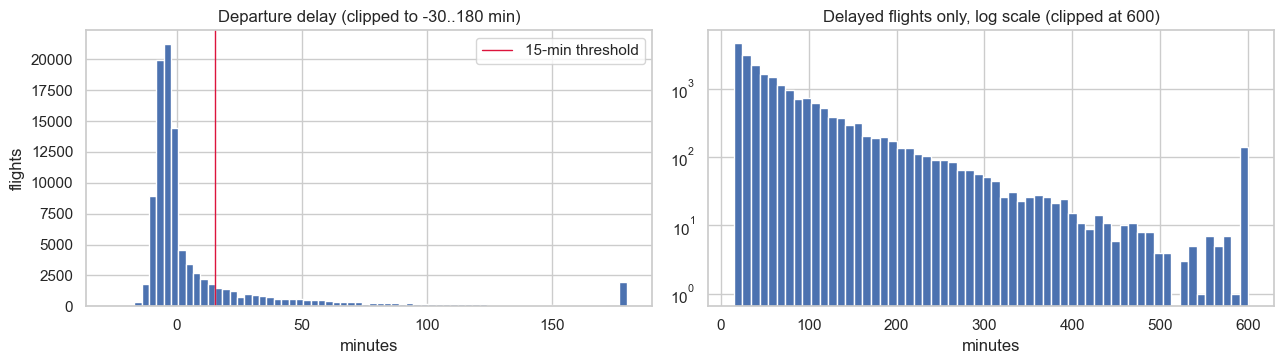

median delay (min)                       -3.0
% departing early                        61.3
% delayed 60+ min                         8.7
% delayed 180+ min                        1.9
% of delayed flights that are 60+ min    41.2


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
d = done.DepDelay
axes[0].hist(d.clip(-30, 180), bins=70, color=BLUE)
axes[0].axvline(15, color="crimson", lw=1, label="15-min threshold")
axes[0].set(title="Departure delay (clipped to -30..180 min)", xlabel="minutes", ylabel="flights")
axes[0].legend()
axes[1].hist(d[d >= 15].clip(upper=600), bins=60, color=BLUE, log=True)
axes[1].set(title="Delayed flights only, log scale (clipped at 600)", xlabel="minutes")
plt.tight_layout(); plt.show()
print(pd.Series({
    "median delay (min)": d.median(),
    "% departing early": 100 * (d < 0).mean(),
    "% delayed 60+ min": 100 * (d >= 60).mean(),
    "% delayed 180+ min": 100 * (d >= 180).mean(),
    "% of delayed flights that are 60+ min": 100 * (d[d >= 15] >= 60).mean(),
}).round(1).to_string())

The typical flight leaves early: the median is −3 minutes and 61% push back before schedule. The tail is long, though. 41% of delayed flights are 60+ minutes late and 1.9% of all flights are 3+ hours late. That suggests a binary label plus, later, a severity model.

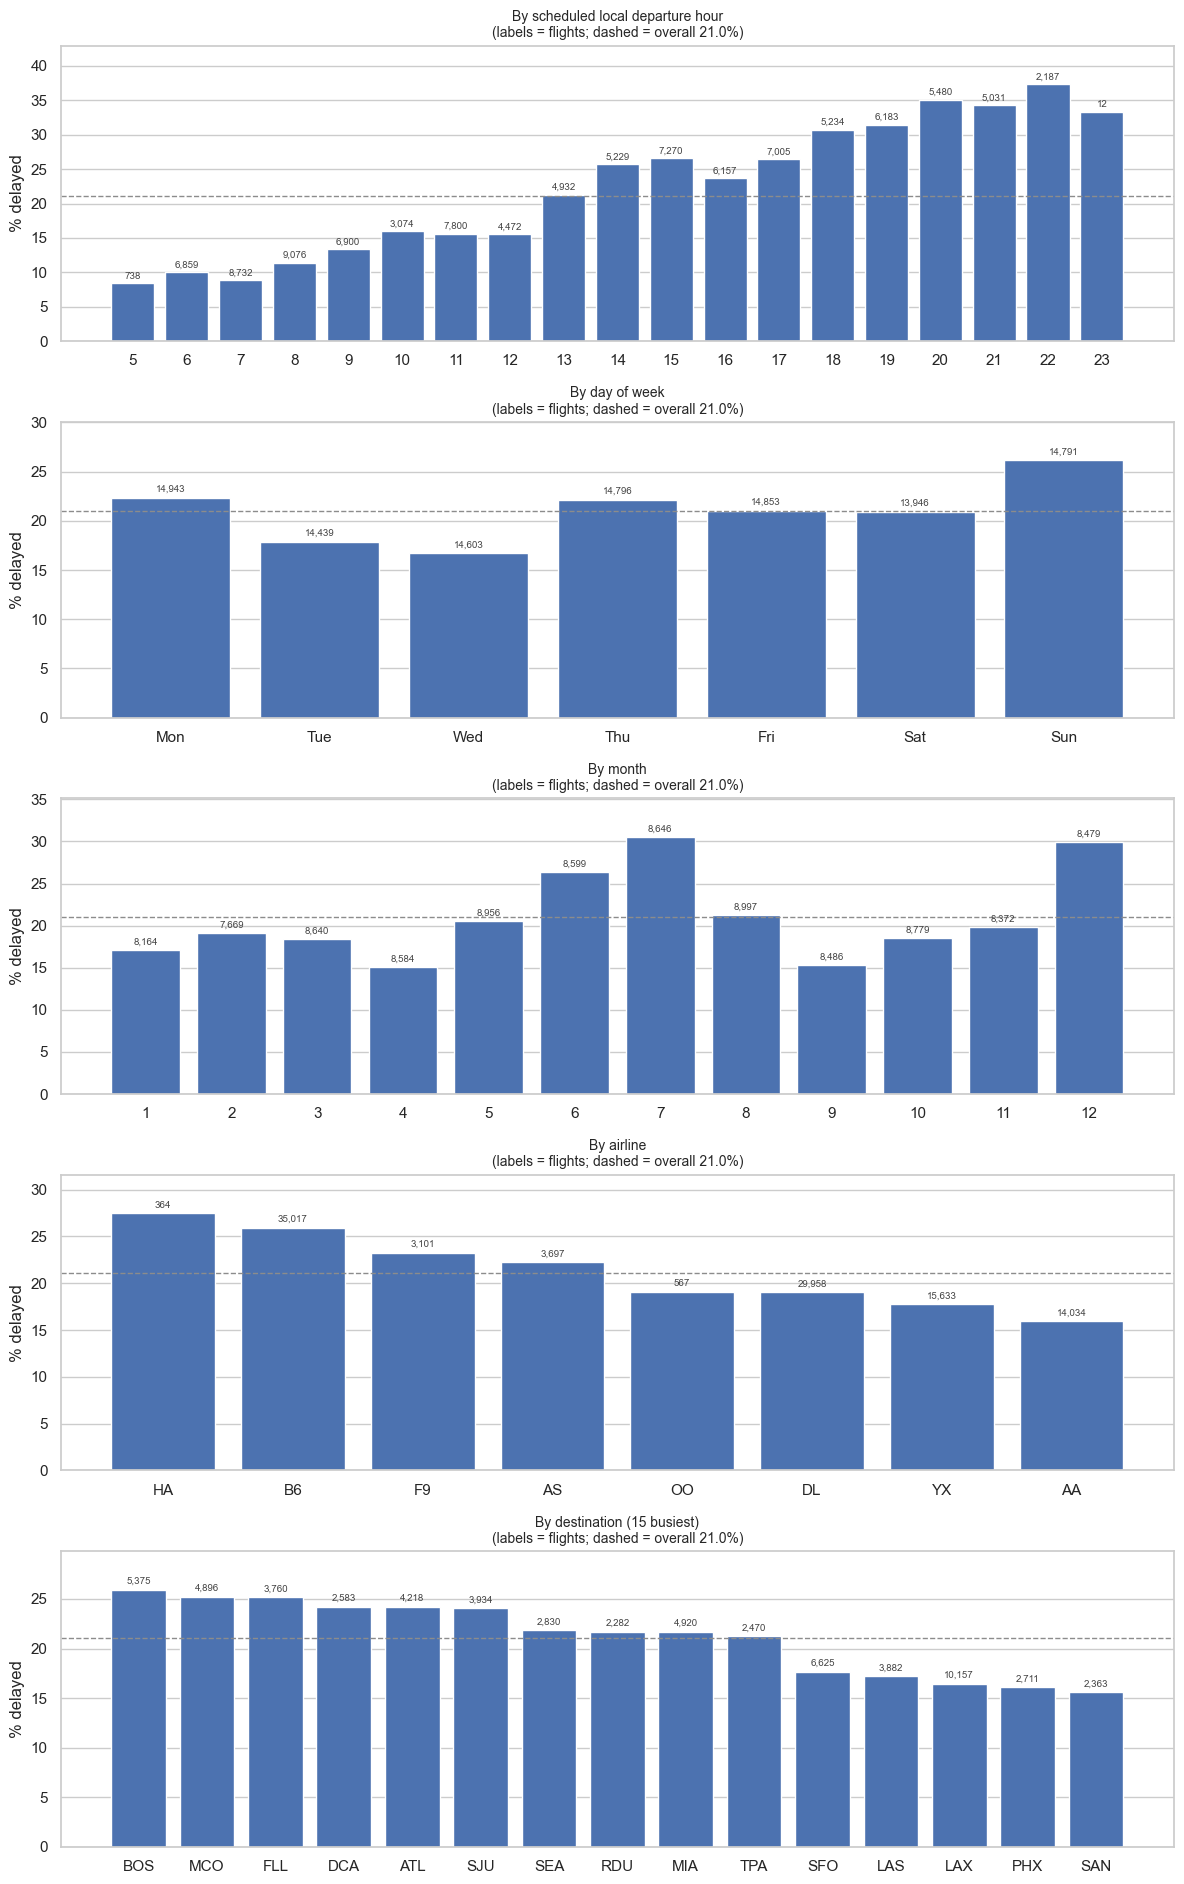

In [19]:
DOW = {1: "Mon", 2: "Tue", 3: "Wed", 4: "Thu", 5: "Fri", 6: "Sat", 7: "Sun"}
fig, axes = plt.subplots(5, 1, figsize=(12, 19))
bar_rate(rate_by(done, "dep_hour"), "By scheduled local departure hour", axes[0])
bar_rate(rate_by(done, "DayOfWeek").rename(index=DOW), "By day of week", axes[1])
bar_rate(rate_by(done, "Month"), "By month", axes[2])
bar_rate(rate_by(done, "Reporting_Airline").sort_values("rate_pct", ascending=False), "By airline", axes[3])
top15 = done.Dest.value_counts().index[:15]
bar_rate(rate_by(done[done.Dest.isin(top15)], "Dest").sort_values("rate_pct", ascending=False),
         "By destination (15 busiest)", axes[4])
plt.tight_layout(); plt.show()

Time of day is the strongest calendar signal. Delays climb from about 8–10% for 05:00–08:00 departures to about 35% after 20:00 as delays build up through the day. Sunday is the worst day (26%) and Tuesday–Wednesday the best (17–18%). June–July (summer thunderstorms) and December are the worst months; April and September are the best. JetBlue (B6, the largest carrier at 35k flights) and Hawaiian run above average, while American (AA) and Republic (YX) run below. Among busy destinations, Boston, Orlando and Fort Lauderdale are worst, and the West Coast routes (LAX, SFO, SAN, PHX, LAS) are best.

### Delay causes

BTS fills the cause columns only when the *arrival* delay is 15+ minutes, so they cover most, not all, departure-delayed flights.

In [20]:
CAUSES = ["CarrierDelay", "WeatherDelay", "NASDelay", "SecurityDelay", "LateAircraftDelay"]
dl = done[done.delayed == 1]
has = dl[CAUSES].notna().any(axis=1)
causes = pd.DataFrame({
    "share of cause minutes %": 100 * dl[CAUSES].sum() / dl[CAUSES].sum().sum(),
    "% of delayed flights with this cause": 100 * (dl.loc[has, CAUSES] > 0).mean(),
}).round(1)
print(f"{has.mean():.1%} of departure-delayed flights have cause data.")
causes

80.5% of departure-delayed flights have cause data.


,share of cause minutes %,% of delayed flights with this cause
CarrierDelay,35.9,64.6
WeatherDelay,3.8,4.4
NASDelay,20.8,50.6
SecurityDelay,0.3,0.7
LateAircraftDelay,39.3,58.1


Late-arriving aircraft (39% of cause minutes) and carrier issues (36%) dominate, followed by the National Airspace System (21%, which includes ATC volume and weather-driven flow programs). Direct "weather" is only 4% because BTS records most weather impact under NAS. The large late-aircraft share means knock-on delays from earlier flights are a key driver.

## 5. Temporal patterns

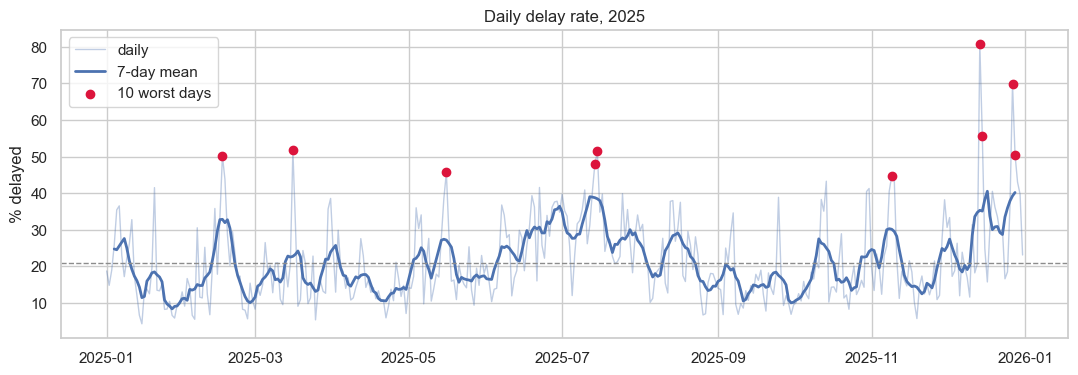

,flights,delayed,rate_pct,weekday
FlightDate,,,,
2025-12-14,198,160,80.8,Sunday
2025-12-27,189,132,69.8,Saturday
2025-12-15,281,156,55.5,Monday
2025-03-16,270,140,51.9,Sunday
2025-07-15,284,146,51.4,Tuesday
2025-12-28,281,142,50.5,Sunday
2025-02-16,247,124,50.2,Sunday
2025-07-14,213,102,47.9,Monday
2025-05-16,276,126,45.7,Friday


In [21]:
daily = rate_by(done, "FlightDate")
daily.index = pd.to_datetime(daily.index)
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(daily.index, daily.rate_pct, color=BLUE, alpha=0.35, lw=1, label="daily")
ax.plot(daily.index, daily.rate_pct.rolling(7, center=True).mean(), color=BLUE, lw=2, label="7-day mean")
worst = daily.nlargest(10, "rate_pct")
ax.scatter(worst.index, worst.rate_pct, color="crimson", zorder=3, label="10 worst days")
ax.axhline(OVERALL, color=GREY, ls="--", lw=1)
ax.set(title="Daily delay rate, 2025", ylabel="% delayed"); ax.legend()
plt.show()
worst.assign(weekday=worst.index.day_name()).round(1)

Delays come in bursts. The worst days (2025-12-14 at 81% and 2025-12-27 at 70%) line up with winter storms, and the July spikes with summer thunderstorms. Several of the top 10 are Sundays, consistent with the weekday pattern.

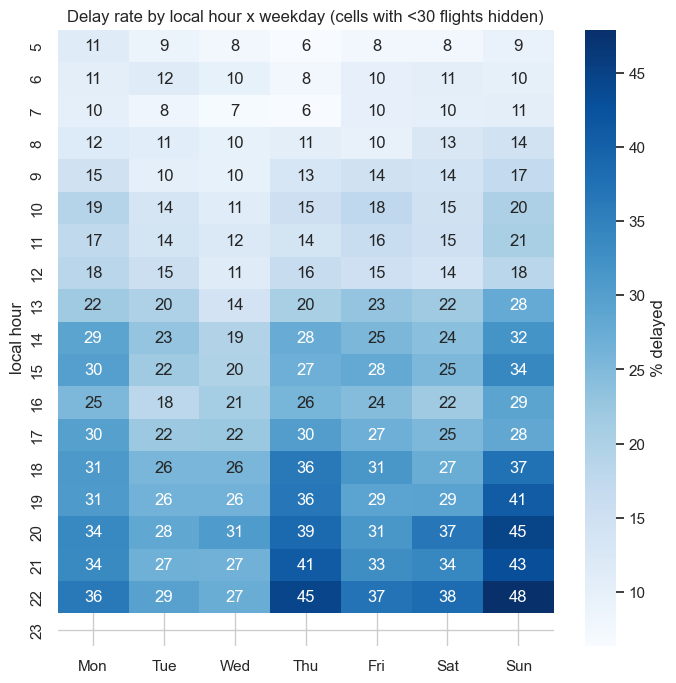

In [22]:
hm = done.pivot_table(index="dep_hour", columns="DayOfWeek", values="delayed", aggfunc="mean") * 100
n = done.pivot_table(index="dep_hour", columns="DayOfWeek", values="delayed", aggfunc="size")
fig, ax = plt.subplots(figsize=(8, 8))
sns.heatmap(hm.where(n >= 30).rename(columns=DOW), annot=True, fmt=".0f", cmap="Blues", ax=ax,
            cbar_kws={"label": "% delayed"})
ax.set(title="Delay rate by local hour x weekday (cells with <30 flights hidden)", xlabel="", ylabel="local hour")
plt.show()

The hour effect is consistent across weekdays: mornings are good every day, evenings are bad every day. Sunday and Monday evenings are the worst cells. Weekday is a smaller effect layered on top of time of day.

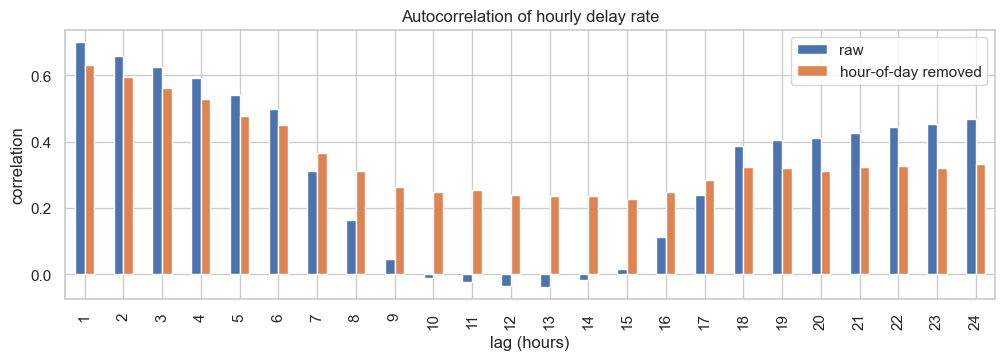

,raw,hour-of-day removed
1,0.70,0.63
2,0.66,0.59
3,0.62,0.56
6,0.50,0.45
12,-0.04,0.24
24,0.47,0.33


In [23]:
hourly_rate = (done.assign(hour=done.sched_dep_utc.dt.floor("h")).groupby("hour")["delayed"].mean() * 100).reindex(FULL)
local_hour = FULL.tz_convert(NY).hour
resid = hourly_rate - hourly_rate.groupby(local_hour).transform("mean")
lags = range(1, 25)
acf = pd.DataFrame({"raw": [hourly_rate.autocorr(l) for l in lags],
                    "hour-of-day removed": [resid.autocorr(l) for l in lags]}, index=lags)
ax = acf.plot(kind="bar", figsize=(12, 3.5), color=[BLUE, "#DD8452"])
ax.set(title="Autocorrelation of hourly delay rate", xlabel="lag (hours)", ylabel="correlation")
plt.show()
acf.loc[[1, 2, 3, 6, 12, 24]].round(2)

Hourly delay rates are highly persistent. The correlation is 0.70 at lag 1 h and still 0.50 at 6 h, and stays at 0.45–0.63 for the first six hours after removing the daily cycle. Recent JFK delay levels (from hours before the prediction time) should be a strong feature.

### Delay propagation by aircraft

This file only has departures from JFK, so the aircraft's inbound flight to JFK is not available. The nearest proxy is the same tail's previous JFK departure within 12 hours (shuttle-style rotations). The `LateAircraftDelay` cause above covers inbound lateness directly.

In [24]:
p = f.dropna(subset=["Tail_Number", "DepDelay"]).sort_values(["Tail_Number", "sched_dep_utc"]).copy()
p["prev_delay"] = p.groupby("Tail_Number")["DepDelay"].shift()
p["gap_h"] = p.groupby("Tail_Number")["sched_dep_utc"].diff().dt.total_seconds() / 3600
near = p[(p.gap_h <= 12) & p.status.isin(["delayed", "on_time"])].copy()
near["delayed"] = (near.status == "delayed").astype(int)
r, pv = stats.spearmanr(near.prev_delay, near.DepDelay)
print(f"{len(near):,} flights whose aircraft departed JFK in the previous 12 h; Spearman r = {r:.2f} (p={pv:.1e})")
near.groupby(near.prev_delay >= 15)["delayed"].agg(flights="size", rate_pct=lambda s: 100 * s.mean()) \
    .rename(index={False: "previous departure on time", True: "previous departure delayed"}).round(1)

17,615 flights whose aircraft departed JFK in the previous 12 h; Spearman r = 0.27 (p=1.8e-290)


,flights,rate_pct
prev_delay,,
previous departure on time,14537,25.4
previous departure delayed,3078,54.0


An aircraft whose previous JFK departure within 12 hours was delayed has a 54% chance of being delayed again, against 25% when the previous departure was on time (Spearman r = 0.27). Only 17.6k flights have such a recent prior JFK departure. Adding the aircraft's inbound flight (BTS rows with `Dest == JFK`) would capture propagation for nearly every flight.

## 6. Destination airports

Does the destination airport relate to departure delays from JFK, overall and at certain times of day?

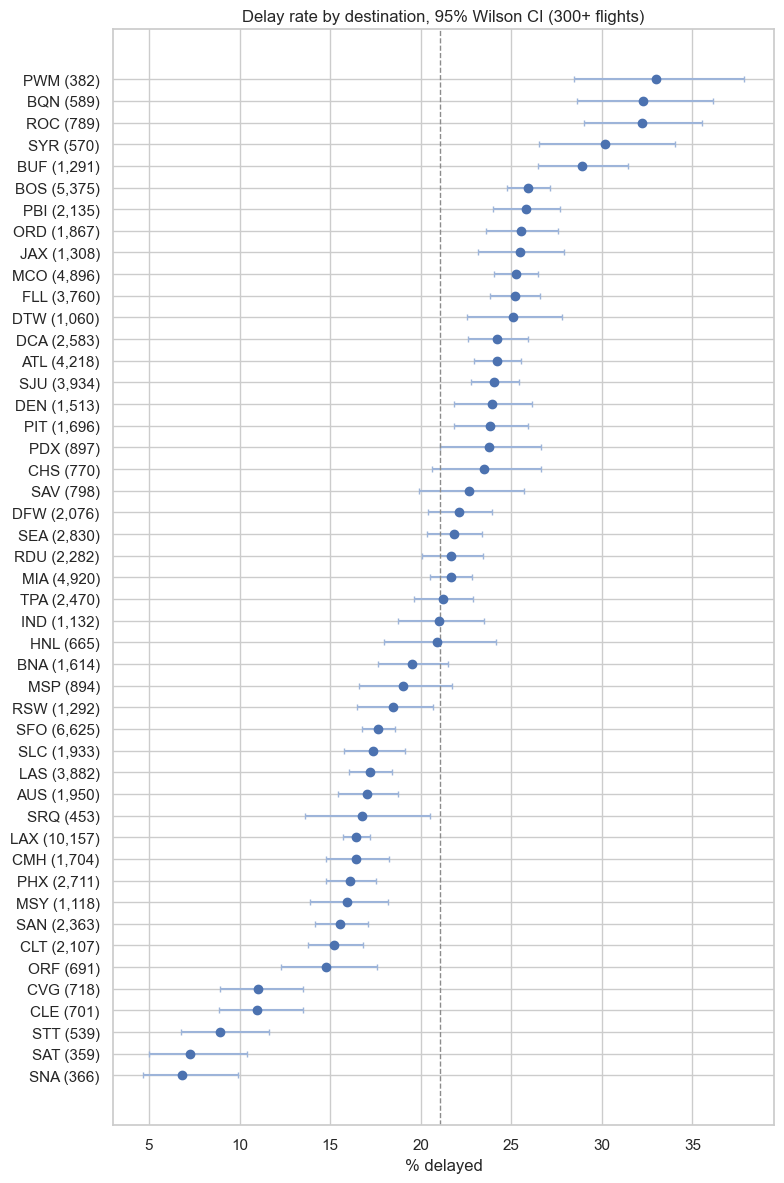

Destinations with fewer than 300 flights (not ranked):


,flights,delayed,rate_pct,ci_low,ci_high
Dest,,,,,
ACK,298,54,18.1,14.2,22.9
MVY,281,53,18.9,14.7,23.8
IAH,254,44,17.3,13.2,22.5
BDL,241,89,36.9,31.1,43.2
PVD,240,79,32.9,27.3,39.1
ORH,183,19,10.4,6.7,15.6
PSP,180,19,10.6,6.9,15.9
SMF,177,58,32.8,26.3,40.0
ONT,177,57,32.2,25.8,39.4


In [25]:
dest = rate_by(done, "Dest")
lo, hi = wilson(dest.delayed, dest.flights)
dest["ci_low"], dest["ci_high"] = 100 * lo, 100 * hi
big = dest[dest.flights >= 300].sort_values("rate_pct")
fig, ax = plt.subplots(figsize=(8, 12))
ax.errorbar(big.rate_pct, range(len(big)), xerr=[big.rate_pct - big.ci_low, big.ci_high - big.rate_pct],
            fmt="o", color=BLUE, ecolor="#9db4d9", capsize=2)
ax.set_yticks(range(len(big))); ax.set_yticklabels([f"{d} ({n:,})" for d, n in zip(big.index, big.flights)])
ax.axvline(OVERALL, color=GREY, ls="--", lw=1)
ax.set(title="Delay rate by destination, 95% Wilson CI (300+ flights)", xlabel="% delayed")
plt.tight_layout(); plt.show()
print("Destinations with fewer than 300 flights (not ranked):")
dest[dest.flights < 300].sort_values("flights", ascending=False).round(1)

In [26]:
grp = done.Dest.where(done.Dest.isin(big.index), "OTHER (<300 flights)")
chi2, pval, dof, _ = stats.chi2_contingency(pd.crosstab(grp, done.delayed))
cramer = np.sqrt(chi2 / len(done))
print(f"Chi-square test of independence (destination x delayed): chi2={chi2:,.0f}, dof={dof}, p={pval:.1e}, Cramér's V={cramer:.3f}")

Chi-square test of independence (destination x delayed): chi2=1,236, dof=47, p=4.0e-228, Cramér's V=0.110


Destination matters (χ² p ≈ 10⁻²²⁸), but the effect is modest (Cramér's V = 0.11). Raw rates range from about 7% (SNA, SAT) to 33% (PWM, BQN, ROC). Small upstate and New England airports look worst raw, but many have wide intervals and are flown by a single airline in evening slots.

### Adjusting for airline and time of day

Expected delays for each flight = the delay rate of its airline x time-of-day block. A destination's observed ÷ expected ratio above 1 means more delays than its airline and departure times alone predict.

,flights,observed,expected,raw_rate_pct,obs_exp,z,top airlines
Dest,,,,,,,
BOS,5375,1394,1163.20,25.93,1.20,7.89,"YX, B6"
MIA,4920,1066,907.83,21.67,1.17,5.95,"AA, DL"
MCO,4896,1236,1090.37,25.25,1.13,5.13,"B6, DL"
ORD,1867,477,390.00,25.55,1.22,5.07,"AA, YX"
ATL,4218,1021,891.58,24.21,1.15,5.00,"DL, B6"
DFW,2076,459,374.75,22.11,1.22,4.89,"AA, DL"
FLL,3760,947,833.15,25.19,1.14,4.59,"B6, DL"
DCA,2583,626,535.93,24.24,1.17,4.51,"YX, B6"
PBI,2135,551,476.07,25.81,1.16,4.01,"B6, DL"


,flights,observed,expected,raw_rate_pct,obs_exp,z,top airlines
Dest,,,,,,,
TPA,2470,524,573.53,21.21,0.91,-2.42,"B6, DL"
CMH,1704,280,319.17,16.43,0.88,-2.48,YX
PHX,2711,436,509.53,16.08,0.86,-3.73,"AA, DL"
SLC,1933,336,431.34,17.38,0.78,-5.36,"DL, B6"
SAN,2363,368,485.42,15.57,0.76,-6.13,"DL, B6"
LAS,3882,668,828.33,17.21,0.81,-6.47,"DL, B6"
SFO,6625,1169,1405.21,17.65,0.83,-7.33,"DL, B6"
LAX,10157,1670,2095.68,16.44,0.80,-10.71,"B6, DL"


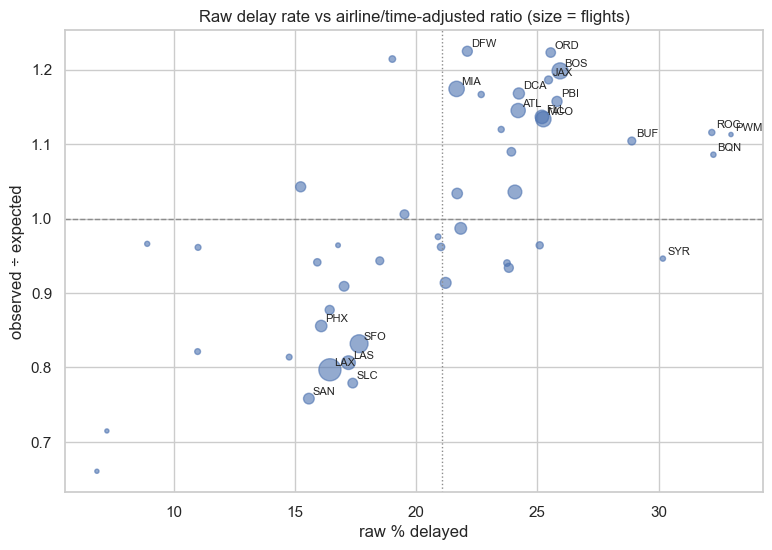

In [27]:
done["expected"] = done.groupby(["Reporting_Airline", "block"], observed=True)["delayed"].transform("mean")

def adjusted(df, col, min_n):
    g = df.groupby(col, observed=True).agg(flights=("delayed", "size"), observed=("delayed", "sum"),
                                           expected=("expected", "sum"),
                                           var=("expected", lambda e: (e * (1 - e)).sum()))
    g["raw_rate_pct"] = 100 * g.observed / g.flights
    g["obs_exp"] = g.observed / g.expected
    g["z"] = (g.observed - g.expected) / np.sqrt(g["var"])
    return g[g.flights >= min_n].drop(columns="var").sort_values("z", ascending=False)

adj = adjusted(done, "Dest", 300)
adj["top airlines"] = [", ".join(done.loc[done.Dest == d, "Reporting_Airline"].value_counts().index[:2]) for d in adj.index]
display(adj.head(12).round(2)); display(adj.tail(8).round(2))

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(adj.raw_rate_pct, adj.obs_exp, s=adj.flights / 40, color=BLUE, alpha=0.6)
for d, row in adj.iterrows():
    if abs(row.z) > 3.5 or row.raw_rate_pct > 27:
        ax.annotate(d, (row.raw_rate_pct, row.obs_exp), fontsize=8, xytext=(3, 3), textcoords="offset points")
ax.axhline(1, color=GREY, ls="--", lw=1); ax.axvline(OVERALL, color=GREY, ls=":", lw=1)
ax.set(title="Raw delay rate vs airline/time-adjusted ratio (size = flights)", xlabel="raw % delayed", ylabel="observed ÷ expected")
plt.show()

After adjusting for airline and time of day, the upstate NY routes (ROC, BUF, SYR) drop out of the top. Their raw excess came from their airline and evening slots. The destinations that remain worse than expected are hubs and congested East Coast or Florida airports: **Boston** (1.20× expected, z = 7.9), Miami (1.17×), Orlando (1.13×), Chicago O'Hare (1.22×), Atlanta (1.15×), Dallas/Fort Worth (1.22×), Fort Lauderdale, Washington National, Palm Beach and Jacksonville. West Coast long-haul routes are much **better** than expected: LAX (0.80×, z = −10.7), SFO, LAS, SAN and SLC, probably because of schedule padding on long flights and fewer destination flow restrictions.

### Destination x time of day

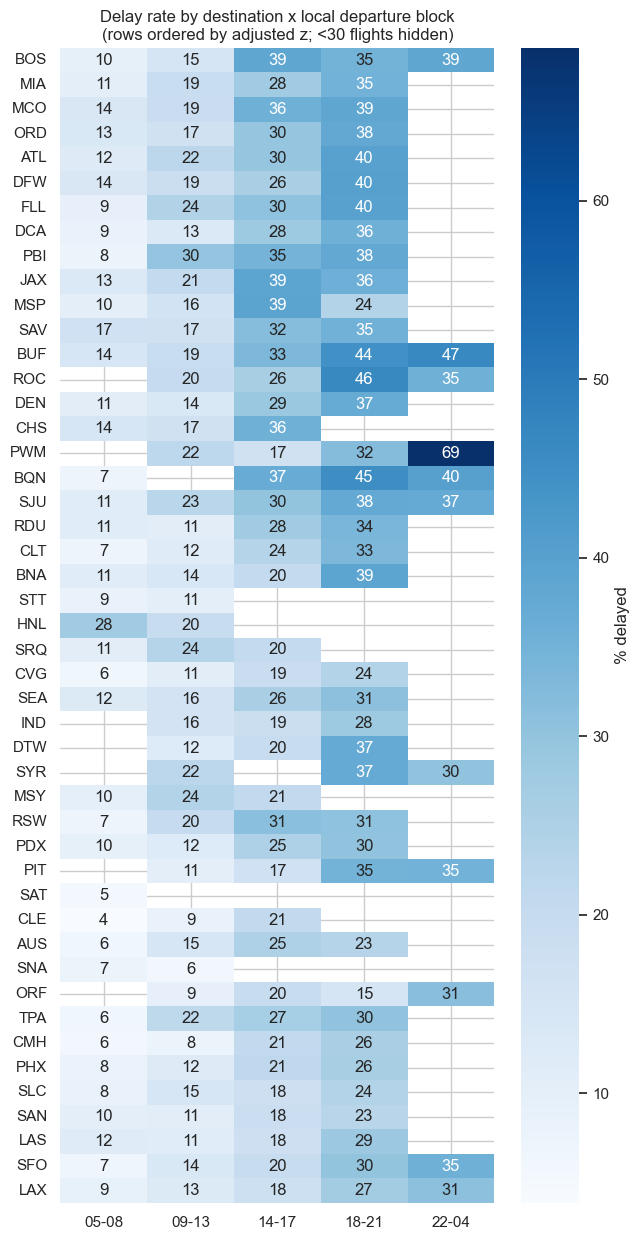

,Dest,block,flights,delayed,rate_pct,block_rate_pct,excess_pts,z
15,BOS,14-17,1441,555,38.5,25.7,12.9,11.2
100,PBI,09-13,416,124,29.8,16.1,13.7,7.6
78,MCO,14-17,1106,393,35.5,25.7,9.9,7.5
56,FLL,09-13,879,213,24.2,16.1,8.1,6.5
3,ATL,09-13,1274,282,22.1,16.1,6.0,5.8
142,SJU,09-13,1047,238,22.7,16.1,6.6,5.8
101,PBI,14-17,718,249,34.7,25.7,9.0,5.5
66,JAX,14-17,276,107,38.8,25.7,13.1,5.0
76,MCO,05-08,1296,181,14.0,10.1,3.9,4.7
120,ROC,18-21,226,105,46.5,32.8,13.6,4.4


In [28]:
hm = done[done.Dest.isin(big.index)].pivot_table(index="Dest", columns="block", values="delayed", aggfunc="mean", observed=True) * 100
n = done[done.Dest.isin(big.index)].pivot_table(index="Dest", columns="block", values="delayed", aggfunc="size", observed=True)
order = adj.index
fig, ax = plt.subplots(figsize=(7, 15))
sns.heatmap(hm.where(n >= 30).loc[order], annot=True, fmt=".0f", cmap="Blues", ax=ax, cbar_kws={"label": "% delayed"})
ax.set(title="Delay rate by destination x local departure block\n(rows ordered by adjusted z; <30 flights hidden)", xlabel="", ylabel="")
plt.show()

blk = done.groupby("block", observed=True)["delayed"].mean()
cells = rate_by(done, ["Dest", "block"], min_n=150).reset_index()
q = cells.block.map(blk).astype(float)
cells["block_rate_pct"] = 100 * q
cells["excess_pts"] = cells.rate_pct - cells.block_rate_pct
cells["z"] = (cells.delayed - cells.flights * q) / np.sqrt(cells.flights * q * (1 - q))
cells.sort_values("z", ascending=False).head(15).round(1)

The strongest destination × time effect is **Boston in the 14:00–17:00 block**: 38.5% delayed against 25.7% for all flights in that block (z = 11.2). Florida destinations are elevated through midday and afternoon: Palm Beach 09:00–13:00 (+13.7 points) and 14:00–17:00, Orlando 14:00–17:00 (+9.9) and Fort Lauderdale 09:00–13:00. Atlanta and San Juan are elevated midday, and Rochester in the evening (46.5%).

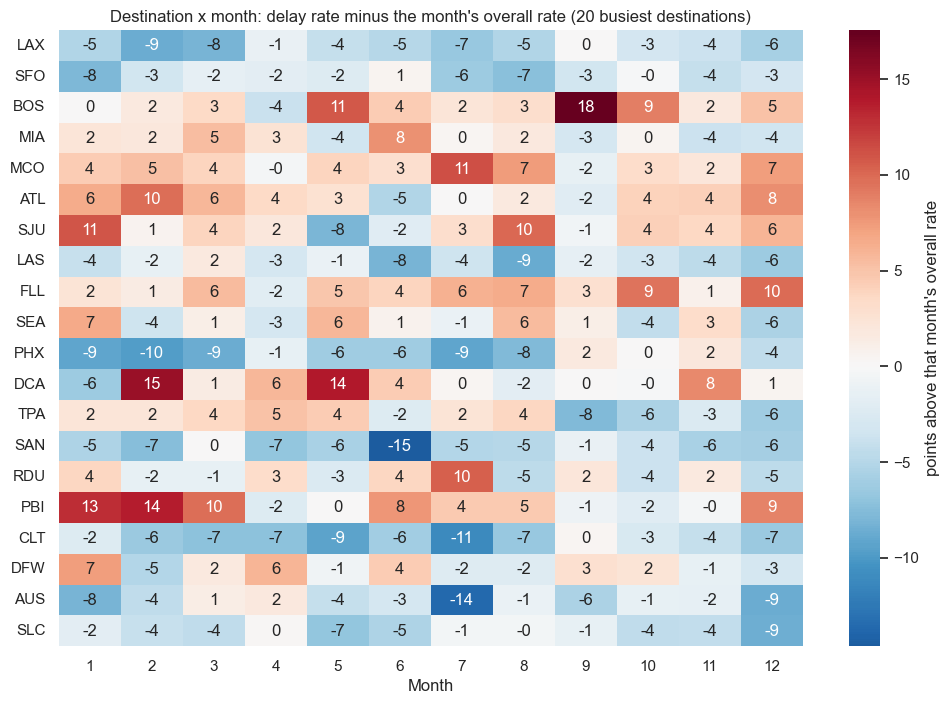

In [29]:
top20 = done.Dest.value_counts().index[:20]
m = done[done.Dest.isin(top20)]
rate = m.pivot_table(index="Dest", columns="Month", values="delayed", aggfunc="mean") * 100
n = m.pivot_table(index="Dest", columns="Month", values="delayed", aggfunc="size")
month_rate = done.groupby("Month")["delayed"].mean() * 100
fig, ax = plt.subplots(figsize=(12, 8))
sns.heatmap((rate - month_rate).where(n >= 30).loc[top20], annot=True, fmt=".0f", cmap="RdBu_r", center=0, ax=ax,
            cbar_kws={"label": "points above that month's overall rate"})
ax.set(title="Destination x month: delay rate minus the month's overall rate (20 busiest destinations)", ylabel="")
plt.show()

Some destination excesses are seasonal. Boston is worst in May and September–October (+11 to +18 points), Palm Beach in January–March (Florida's winter peak season), Washington National in February and May, and Orlando in July–August. Phoenix, Charlotte and the West Coast airports stay below the monthly average almost all year. A destination × season interaction feature is worth testing.

**Caveat.** Destination effects are associations, not causes. They may reflect congestion or weather at the destination (ground delay programs hold JFK departures), flight length and schedule padding, or the airline and aircraft mix that remains after the airline × time adjustment.

## 7. Aircraft type and capacity

`aircraft_capacity_jfk_2025.csv` maps each tail number to its model (OpenSky aircraft database) and the type's maximum certified passengers (exit limit), and is built by `src/scripts/build_aircraft_capacity.py`. The seat values were compiled from published manufacturer specifications without being re-checked online, so treat them as approximate. `max_seats` is the type's maximum, not the airline's cabin layout, and how full each flight was is unknown.

In [30]:
ac = aircraft.rename(columns={"tail_number": "Tail_Number"})
fa = done.merge(ac[["Tail_Number", "typecode", "max_seats", "body", "category", "matched", "type_plausible"]],
                on="Tail_Number", how="left")
print(f"Tails: {aircraft.matched.sum():,} of {len(aircraft):,} matched to OpenSky; "
      f"{aircraft.max_seats.notna().sum():,} have max_seats.")
print(f"Completed flights with max_seats: {fa.max_seats.notna().mean():.1%}")
print("Implausible matches (registration reused):", aircraft.loc[aircraft.matched & ~aircraft.type_plausible, ["tail_number", "model"]].values.tolist())
print("Types with no sourced seat count:", sorted(aircraft.loc[aircraft.type_plausible & aircraft.max_seats.isna(), "typecode"].unique()))
un = aircraft[~aircraft.matched].groupby("airline").size().rename("unmatched tails").to_frame()
un["unmatched flights"] = fa[fa.matched != True].groupby("Reporting_Airline").size()
un.sort_values("unmatched tails", ascending=False)

Tails: 2,265 of 2,569 matched to OpenSky; 2,251 have max_seats.
Completed flights with max_seats: 79.9%
Implausible matches (registration reused): [['N3145J', 'SNJ-5 Texan'], ['N4076J', 'Citation M2'], ['N709AL', 'S-76 A']]
Types with no sourced seat count: ['B788']


,unmatched tails,unmatched flights
airline,,
DL,88,5823
AA,59,1364
B6,53,10496
F9,52,1583
AS,46,817
HA,3,101
OO,3,35


80% of completed flights have a seat count. Coverage is weakest for **JetBlue**: 53 unmatched tails carry 10,496 flights, mostly recent deliveries missing from OpenSky's snapshot. Aircraft results therefore under-represent JetBlue, the airline with the most delays. The FAA registry would close the gap if downloaded manually. The 787-8 has no sourced seat count, and 3 tails matched non-airliner types (reused registrations) and are excluded.

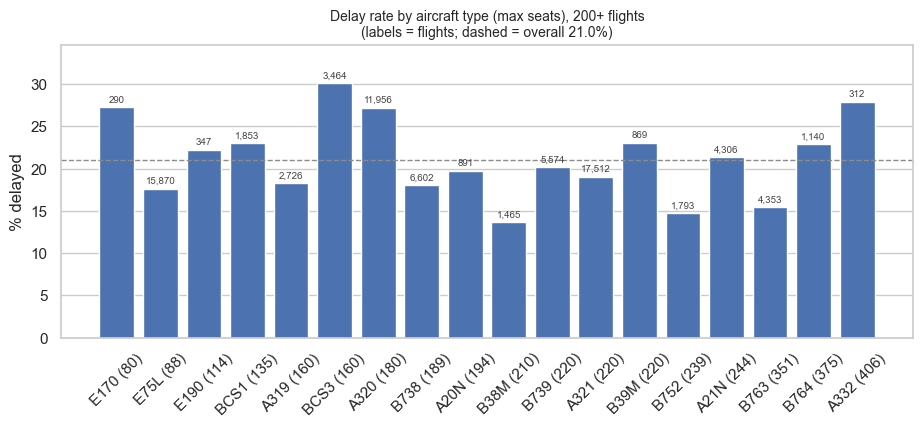

,flights,observed,expected,raw_rate_pct,obs_exp,z
seat_bin,,,,,,
<100,16165,2879,2878.06,17.81,1.00,0.02
100-180,20346,5292,4910.22,26.01,1.08,6.45
181-250,39012,7400,7817.29,18.97,0.95,-5.44
>250,6306,1141,1211.94,18.09,0.94,-2.31


In [31]:
types = rate_by(fa[fa.type_plausible == True], "typecode", min_n=200).join(aircraft.groupby("typecode").max_seats.first()).sort_values("max_seats")
types.index = [f"{t} ({int(s) if pd.notna(s) else '?'})" for t, s in zip(types.index, types.max_seats)]
bar_rate(types, "Delay rate by aircraft type (max seats), 200+ flights", rotate=45)
plt.show()

fa["seat_bin"] = pd.cut(fa.max_seats, [0, 99, 180, 250, 1000], labels=["<100", "100-180", "181-250", ">250"])
bins = adjusted(fa, "seat_bin", 0).sort_index()
bins.round(2)

Raw rates by type mostly reflect who flies them. The JetBlue types (A220-300/BCS3 30%, A320 27%) are high, and the Republic E175 (E75L, 17.5%) and American 737 MAX 8 (B38M, 13.6%) are low. By seat bin after the airline × time adjustment, only the 100–180-seat bin is worse than expected (1.08×, z = 6.5), while 181–250 (0.95×) and >250 seats (0.94×) are slightly better.

In [32]:
sub = fa.dropna(subset=["max_seats"])
rows = [["all flights", len(sub), *stats.pointbiserialr(sub.delayed, sub.max_seats)]]
for a, g in sub.groupby("Reporting_Airline"):
    if len(g) >= 500 and g.max_seats.nunique() > 1:
        rows.append([f"airline {a}", len(g), *stats.pointbiserialr(g.delayed, g.max_seats)])
for b, g in sub.groupby("block", observed=True):
    rows.append([f"block {b}", len(g), *stats.pointbiserialr(g.delayed, g.max_seats)])
display(pd.DataFrame(rows, columns=["subset", "flights", "point-biserial r", "p"]).round(4))

for by in ["Reporting_Airline", "block"]:
    r = sub.pivot_table(index=by, columns="seat_bin", values="delayed", aggfunc="mean", observed=True) * 100
    n = sub.pivot_table(index=by, columns="seat_bin", values="delayed", aggfunc="size", observed=True)
    print(f"% delayed by seat bin within {by} (cells with <100 flights hidden)")
    display(r.where(n >= 100).round(1))

,subset,flights,point-biserial r,p
0,all flights,81829,-0.0032,0.3603
1,airline AA,12652,0.0057,0.5198
2,airline AS,2864,0.0072,0.6999
3,airline B6,24232,-0.0744,0.0000
4,airline DL,24135,-0.0196,0.0024
5,airline F9,1518,0.0422,0.0999
6,airline OO,532,0.0515,0.2354
7,airline YX,15633,-0.0341,0.0000
8,block 05-08,20040,0.0396,0.0000
9,block 09-13,21788,0.0353,0.0000


% delayed by seat bin within Reporting_Airline (cells with <100 flights hidden)


seat_bin,<100,100-180,181-250,>250
Reporting_Airline,,,,
AA,NaN,19.6,15.5,23.2
AS,NaN,NaN,22.3,NaN
B6,NaN,28.3,21.0,NaN
DL,NaN,19.8,19.3,17.4
F9,NaN,NaN,22.5,NaN
HA,NaN,NaN,NaN,28.1
OO,19.2,NaN,NaN,NaN
YX,17.8,NaN,NaN,NaN


% delayed by seat bin within block (cells with <100 flights hidden)


seat_bin,<100,100-180,181-250,>250
block,,,,
05-08,7.6,10.2,8.6,13.3
09-13,10.4,21.9,14.7,15.1
14-17,22.6,31.4,24.0,20.9
18-21,28.2,37.6,32.0,25.8
22-04,22.3,41.6,33.3,NaN


Overall, `max_seats` has **no linear correlation** with delays (point-biserial r = −0.003, p = 0.36). Within airlines the relationship is weak and inconsistent. At JetBlue, smaller aircraft are delayed more (r = −0.07; A320/A220 at 28% against A321 at 21%), likely because they fly the short Boston and Florida routes. At American, widebodies are worse (23% against 16% for 181–250 seats). Aircraft size is a proxy for route and airline, not an independent cause.

In [33]:
display(adjusted(fa, "body", 0).round(2))
display(adjusted(fa, "category", 0).round(2))
print("Regional jets by airline:", fa[fa.category == "regional"].Reporting_Airline.value_counts().to_dict())

,flights,observed,expected,raw_rate_pct,obs_exp,z
body,,,,,,
narrowbody,75526,15573,15605.90,20.62,1.00,-0.30
widebody,6321,1147,1215.29,18.15,0.94,-2.22


,flights,observed,expected,raw_rate_pct,obs_exp,z
category,,,,,,
regional,16512,2956,2969.57,17.90,1.00,-0.28
mainline,65335,13764,13851.62,21.07,0.99,-0.86


Regional jets by airline: {'YX': 15633, 'OO': 532, 'B6': 347}


Widebodies are slightly less delayed than expected (0.94×), and narrowbodies are on expectation. Regional jets match expectation (1.00×), but almost all are flown by Republic (YX), so "regional" is hard to separate from the airline. For modelling, aircraft type may add a little signal through route and rotation patterns. Seat capacity alone is unlikely to help.

## 8. Delays vs other sources

Completed flights are aggregated to their scheduled UTC departure hour and joined to:
- **IEM:** the latest routine (:51) observation before the hour, so `HH:51` describes hour `HH+1`, plus present-weather flags from any report in the preceding hour.
- **Open-Meteo:** the forecast valid for that hour.
- **FAA ASPM (synthetic):** the same hour. Its relationships are built into the generator and are **not findings**.

Hours with fewer than 5 departures are dropped from the hourly correlations.

In [34]:
sky = iem.copy()
sky["hour"] = sky.valid_utc.dt.floor("h") + pd.Timedelta(hours=1)
ceiling = pd.Series(np.nan, index=sky.index)
for i in [4, 3, 2, 1]:
    ok = sky[f"skyc{i}"].isin(["BKN", "OVC", "VV"])
    ceiling = ceiling.mask(ok, sky[f"skyl{i}"])
sky["ceiling_ft"] = ceiling.fillna(12000).clip(upper=12000)

routine = sky[sky.metar_minute == 51].sort_values("valid_utc").drop_duplicates("hour", keep="last").set_index("hour")
iem_h = pd.DataFrame({
    "iem_temp_f": routine.tmpf, "iem_dewpt_f": routine.dwpf, "iem_relh": routine.relh,
    "iem_wind_kt": routine.sknt, "iem_gust_kt": routine.gust.fillna(routine.sknt),
    "iem_vis_mi": routine.vsby, "iem_ceiling_ft": routine.ceiling_ft,
    "iem_precip_in": routine.p01i.fillna(0), "iem_mslp": routine.mslp,
})
wx = sky.wxcodes.fillna("")
flags = pd.DataFrame({"hour": sky.hour, "iem_snow": wx.str.contains("SN"), "iem_thunder": wx.str.contains("TS"),
                      "iem_fog": wx.str.contains("FG"), "iem_rain": wx.str.contains("RA|DZ"),
                      "iem_freezing": wx.str.contains("FZ|PL")}).groupby("hour").max()
iem_h = iem_h.join(flags)

fc_h = fc.set_index("time_utc").drop(columns="time_local").add_prefix("fc_")
aspm_h = aspm.set_index("hour_utc").drop(columns=["hour_local", "local_date", "local_hour", "is_synthetic"]).add_prefix("aspm_")

done["hour"] = done.sched_dep_utc.dt.floor("h")
fh = done.groupby("hour").agg(flights=("delayed", "size"), delay_rate=("delayed", "mean"), mean_delay=("DepDelay", "mean"))
fh["delay_rate"] *= 100
hourly = fh.join(iem_h).join(fc_h).join(aspm_h)
# Delay rate minus the average for that local hour, to separate weather from the daily cycle.
hourly["delay_resid"] = hourly.delay_rate - hourly.groupby(hourly.index.tz_convert(NY).hour).delay_rate.transform("mean")
H = hourly[hourly.flights >= 5]
print(f"{len(hourly):,} hours with departures; {len(H):,} with 5+ departures. "
      f"Hours lacking a routine IEM report: {hourly.iem_temp_f.isna().sum()}")
H.head()

6,517 hours with departures; 6,104 with 5+ departures. Hours lacking a routine IEM report: 2


,flights,delay_rate,mean_delay,iem_temp_f,iem_dewpt_f,iem_relh,iem_wind_kt,iem_gust_kt,iem_vis_mi,iem_ceiling_ft,iem_precip_in,iem_mslp,iem_snow,iem_thunder,iem_fog,iem_rain,iem_freezing,fc_temperature_2m,fc_relative_humidity_2m,fc_dew_point_2m,fc_precipitation,fc_rain,fc_snowfall,fc_weather_code,fc_cloud_cover,fc_cloud_cover_low,fc_visibility,fc_pressure_msl,fc_wind_speed_10m,fc_wind_direction_10m,fc_wind_gusts_10m,aspm_runway_config,aspm_arrival_runways,aspm_departure_runways,aspm_met_condition,aspm_airport_arrival_rate,aspm_airport_departure_rate,aspm_scheduled_departures,aspm_scheduled_arrivals,aspm_cancelled_departures,aspm_cancelled_arrivals,aspm_actual_departures,aspm_actual_arrivals,aspm_departure_queue_end,aspm_arrival_queue_end,aspm_avg_taxi_out_min,aspm_avg_taxi_in_min,aspm_avg_departure_delay_min,aspm_pct_ontime_departures,delay_resid
hour,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2025-01-01 11:00:00+00:00,18,11.111111,-0.555556,47.0,44.0,89.24,11.0,11.0,10.0,11000.0,0.0,998.9,False,False,False,False,False,7.8,91,6.4,0.0,0.0,0.0,0,3,3,14000.0,998.7,10.5,254,34.2,"22L|22R,31L",22L,"22R,31L",VMC,56,52,28,20,0,0,28,20,0,0,18.6,8.0,4.9,87.7,1.064887
2025-01-01 12:00:00+00:00,23,4.347826,3.347826,47.0,44.0,89.24,11.0,11.0,8.0,6000.0,0.0,999.2,False,False,False,False,False,8.0,89,6.3,0.0,0.0,0.0,3,100,100,14700.0,999.0,11.1,260,28.1,"22L|22R,31L",22L,"22R,31L",VMC,56,52,34,22,0,0,34,22,0,0,18.5,8.1,2.6,90.6,-4.672418
2025-01-01 13:00:00+00:00,20,45.000000,26.900000,48.0,44.0,85.95,12.0,12.0,10.0,1000.0,0.0,999.2,False,False,False,False,False,8.1,89,6.4,0.0,0.0,0.0,3,100,100,14700.0,998.8,12.9,267,37.8,"22L|22R,31L",22L,"22R,31L",VMC,56,52,31,22,0,0,31,22,0,0,21.5,9.3,4.4,87.0,33.290612
2025-01-01 14:00:00+00:00,19,10.526316,1.263158,49.0,45.0,86.00,12.0,12.0,10.0,6500.0,0.0,999.8,False,False,False,False,False,8.5,89,6.8,0.0,0.0,0.0,0,3,3,15200.0,999.6,15.8,255,37.4,"22L|22R,31L",22L,"22R,31L",VMC,56,52,28,25,0,0,28,25,0,0,19.7,9.3,2.9,93.6,-2.839369
2025-01-01 15:00:00+00:00,11,9.090909,1.636364,49.0,45.0,86.00,12.0,12.0,10.0,1200.0,0.0,1000.3,False,False,False,False,False,9.2,87,7.2,0.0,0.0,0.0,3,100,100,16300.0,1000.1,18.0,252,39.2,"22L|22R,31L",22L,"22R,31L",VMC,56,52,24,26,0,0,24,26,0,0,15.8,10.1,4.9,87.7,-7.005786


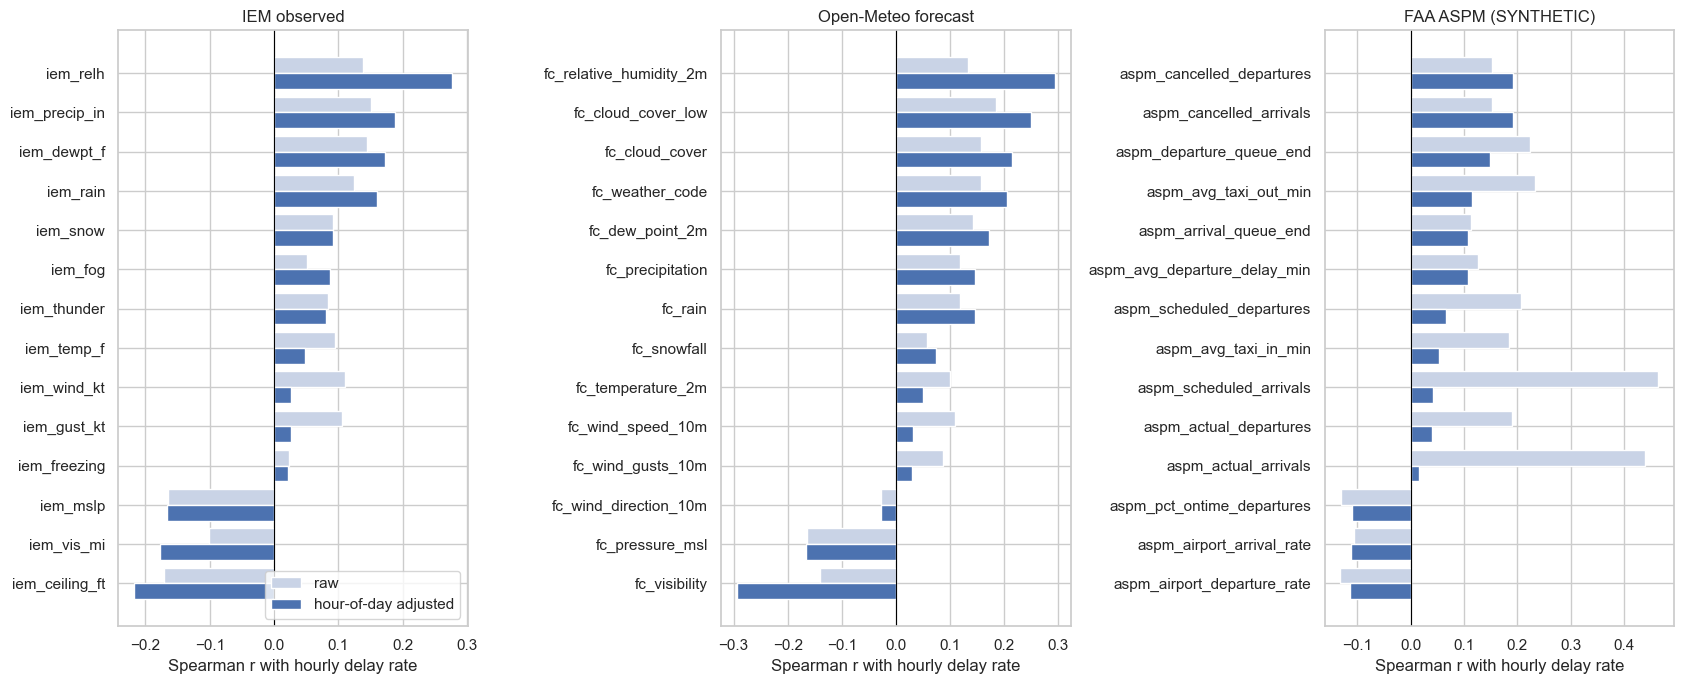

,source,feature,spearman_r,p,spearman_r_hour_adj,hours
15,Open-Meteo forecast,fc_relative_humidity_2m,0.134,0.0,0.294,6104
23,Open-Meteo forecast,fc_visibility,-0.141,0.0,-0.293,6104
2,IEM observed,iem_relh,0.139,0.0,0.276,6102
22,Open-Meteo forecast,fc_cloud_cover_low,0.185,0.0,0.250,6104
6,IEM observed,iem_ceiling_ft,-0.171,0.0,-0.218,6102
21,Open-Meteo forecast,fc_cloud_cover,0.157,0.0,0.215,6104
20,Open-Meteo forecast,fc_weather_code,0.157,0.0,0.205,6104
32,FAA ASPM (SYNTHETIC),aspm_cancelled_departures,0.153,0.0,0.192,6104
33,FAA ASPM (SYNTHETIC),aspm_cancelled_arrivals,0.152,0.0,0.192,6104
7,IEM observed,iem_precip_in,0.150,0.0,0.189,6102


In [35]:
SOURCES = {"IEM observed": [c for c in H if c.startswith("iem_")],
           "Open-Meteo forecast": [c for c in H if c.startswith("fc_")],
           "FAA ASPM (SYNTHETIC)": [c for c in H if c.startswith("aspm_") and H[c].dtype != object]}
rows = []
for src, cols in SOURCES.items():
    for c in cols:
        x = H[[c, "delay_rate", "delay_resid"]].dropna().astype(float)
        r, pv = stats.spearmanr(x[c], x.delay_rate)
        ra = stats.spearmanr(x[c], x.delay_resid)[0]
        rows.append([src, c, r, pv, ra, len(x)])
spear = pd.DataFrame(rows, columns=["source", "feature", "spearman_r", "p", "spearman_r_hour_adj", "hours"])
fig, axes = plt.subplots(1, 3, figsize=(17, 7))
for ax, (src, g) in zip(axes, spear.groupby("source", sort=False)):
    g = g.sort_values("spearman_r_hour_adj")
    y = np.arange(len(g))
    ax.barh(y + 0.2, g.spearman_r, height=0.4, color="#c9d3e6", label="raw")
    ax.barh(y - 0.2, g.spearman_r_hour_adj, height=0.4, color=BLUE, label="hour-of-day adjusted")
    ax.set_yticks(y); ax.set_yticklabels(g.feature)
    ax.axvline(0, color="black", lw=0.8); ax.set(title=src, xlabel="Spearman r with hourly delay rate")
axes[0].legend(loc="lower right")
plt.tight_layout(); plt.show()
display(spear.reindex(spear.spearman_r_hour_adj.abs().sort_values(ascending=False).index).groupby("source", sort=False).head(5).round(3))

**Before adjusting for hour of day**, the ASPM fields (synthetic) and humidity, low cloud, pressure and precipitation correlate with the hourly delay rate. **After adjusting**, wind speed and gusts lose almost all their correlation because they mainly tracked the afternoon cycle. Moisture and visibility signals get stronger: forecast humidity (r = 0.29), forecast visibility (−0.29), observed humidity (0.28), forecast low cloud (0.25), observed ceiling (−0.22) and observed precipitation (0.19). The ASPM correlations are built into the synthetic generator and are not findings.

In [36]:
fl = done.join(hourly.drop(columns=["flights", "delay_rate", "mean_delay"]), on="hour")
rows = []
for src, cols in SOURCES.items():
    for c in cols:
        x = fl[[c, "delayed"]].dropna()
        x[c] = x[c].astype(float)
        if x[c].nunique() > 1:
            r, pv = stats.pointbiserialr(x.delayed, x[c])
            rows.append([src, c, r, pv, len(x)])
pb = pd.DataFrame(rows, columns=["source", "feature", "point_biserial_r", "p", "flights"])
pb.reindex(pb.point_biserial_r.abs().sort_values(ascending=False).index).groupby("source", sort=False).head(6).round(4)

,source,feature,point_biserial_r,p,flights
31,FAA ASPM (SYNTHETIC),aspm_scheduled_arrivals,0.1949,0.0,102371
35,FAA ASPM (SYNTHETIC),aspm_actual_arrivals,0.1832,0.0,102371
38,FAA ASPM (SYNTHETIC),aspm_avg_taxi_out_min,0.1365,0.0,102371
40,FAA ASPM (SYNTHETIC),aspm_avg_departure_delay_min,0.1216,0.0,102371
36,FAA ASPM (SYNTHETIC),aspm_departure_queue_end,0.1196,0.0,102371
41,FAA ASPM (SYNTHETIC),aspm_pct_ontime_departures,-0.1192,0.0,102371
22,Open-Meteo forecast,fc_cloud_cover_low,0.0880,0.0,102371
6,IEM observed,iem_ceiling_ft,-0.0845,0.0,102341
24,Open-Meteo forecast,fc_pressure_msl,-0.0793,0.0,102371
8,IEM observed,iem_mslp,-0.0790,0.0,102307


Per-flight correlations are smaller (|r| ≤ 0.09 for real weather) because one hour's weather is shared by many flights with different outcomes. The ranking matches the hourly view: low cloud, ceiling, pressure (storm systems) and humidity lead. The ASPM rows are synthetic.

### Delay rate by binned feature

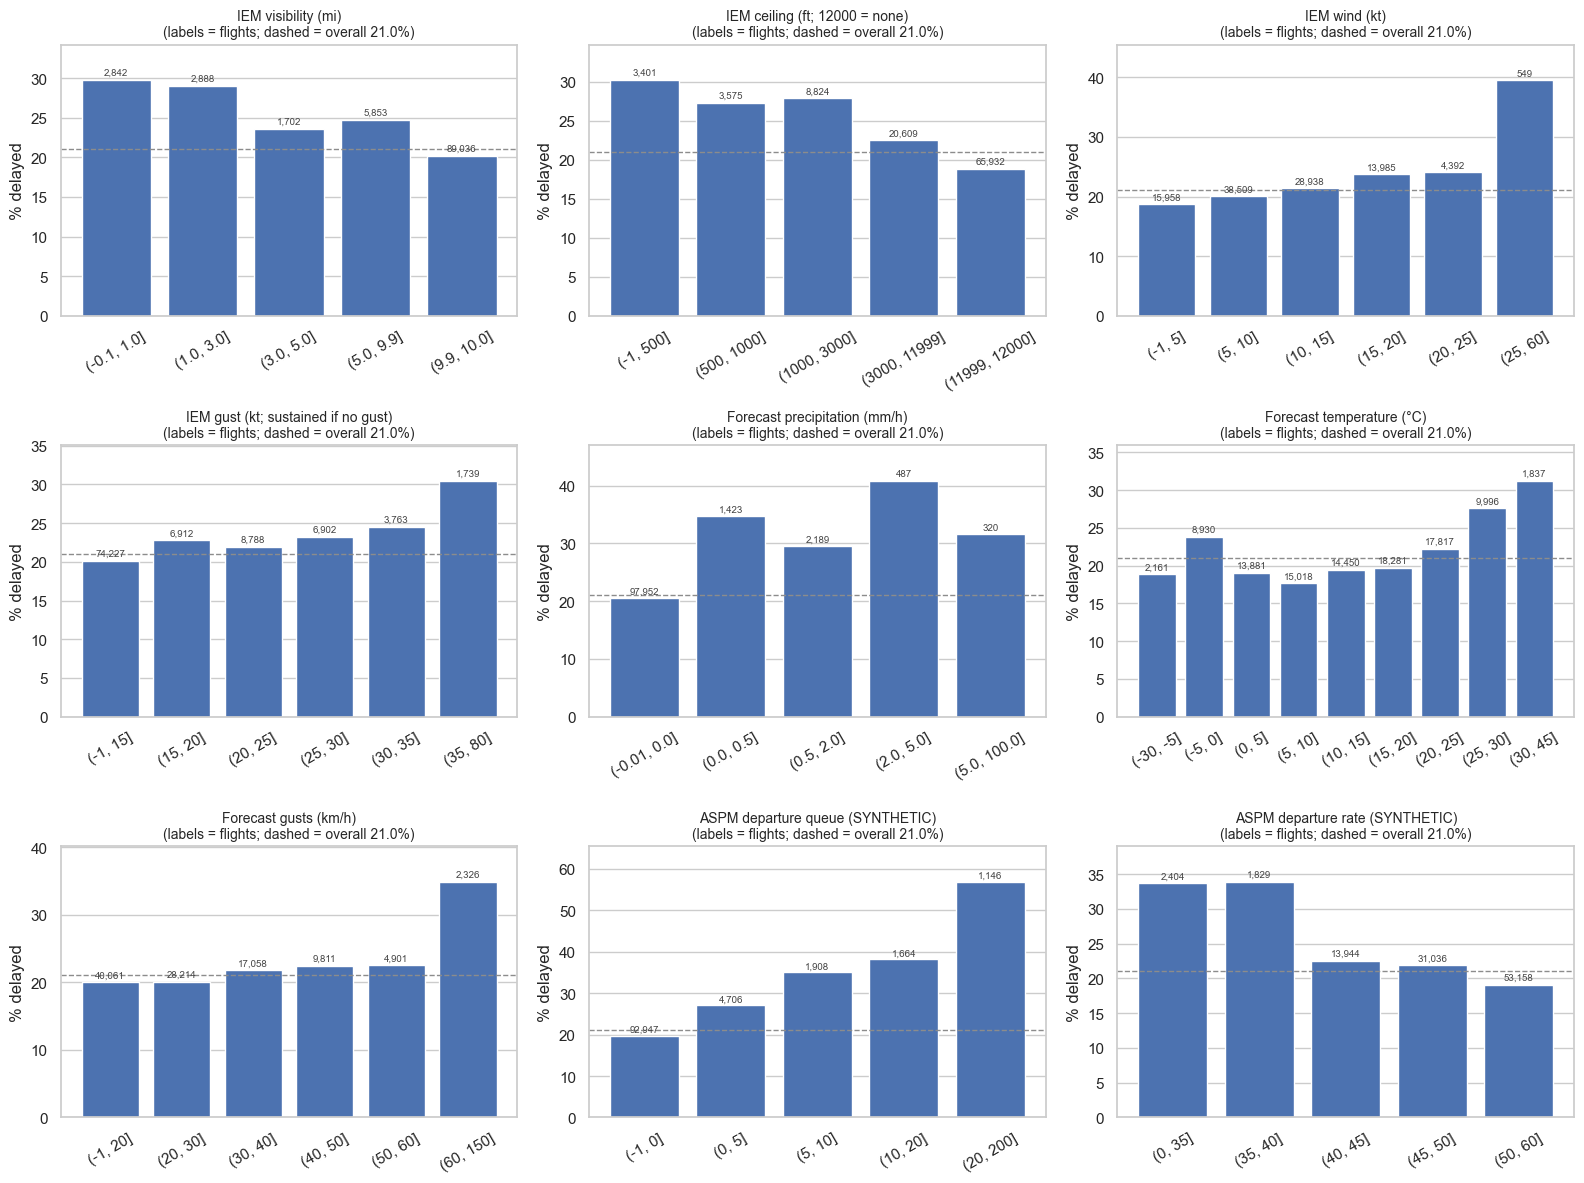

In [37]:
BINNED = [
    ("iem_vis_mi", [-0.1, 1, 3, 5, 9.9, 10], "IEM visibility (mi)"),
    ("iem_ceiling_ft", [-1, 500, 1000, 3000, 11999, 12000], "IEM ceiling (ft; 12000 = none)"),
    ("iem_wind_kt", [-1, 5, 10, 15, 20, 25, 60], "IEM wind (kt)"),
    ("iem_gust_kt", [-1, 15, 20, 25, 30, 35, 80], "IEM gust (kt; sustained if no gust)"),
    ("fc_precipitation", [-0.01, 0, 0.5, 2, 5, 100], "Forecast precipitation (mm/h)"),
    ("fc_temperature_2m", [-30, -5, 0, 5, 10, 15, 20, 25, 30, 45], "Forecast temperature (°C)"),
    ("fc_wind_gusts_10m", [-1, 20, 30, 40, 50, 60, 150], "Forecast gusts (km/h)"),
    ("aspm_departure_queue_end", [-1, 0, 5, 10, 20, 200], "ASPM departure queue (SYNTHETIC)"),
    ("aspm_airport_departure_rate", [0, 35, 40, 45, 50, 60], "ASPM departure rate (SYNTHETIC)"),
]
fig, axes = plt.subplots(3, 3, figsize=(16, 12))
for ax, (col, edges, title) in zip(axes.flat, BINNED):
    t = rate_by(fl.assign(bin=pd.cut(fl[col], edges)), "bin")
    bar_rate(t, title, ax, rotate=30)
plt.tight_layout(); plt.show()

The binned views show clear threshold effects. Visibility under 3 miles and ceilings under 1,000 ft raise delays to about 28–30% (from about 19–20% in clear conditions). Sustained wind of 25+ kt (39%), gusts of 35+ kt (30%) and forecast gusts of 60+ km/h (35%) are strongly worse, even though wind correlates weakly overall, because the effect sits in the tail. Any forecast precipitation lifts the rate to 30–40%. Hot hours (forecast 25–30+ °C, 28–31%) reflect summer thunderstorm season. The ASPM panels are synthetic.

In [38]:
cats = []
for col in ["iem_snow", "iem_thunder", "iem_fog", "iem_rain", "iem_freezing"]:
    t = rate_by(fl, col).reset_index().rename(columns={col: "value"}); t.insert(0, "feature", col); cats.append(t)
for col in ["aspm_met_condition", "aspm_runway_config"]:
    t = rate_by(fl, col).reset_index().rename(columns={col: "value"}); t.insert(0, "feature", col + " (SYNTHETIC)"); cats.append(t)
pd.concat(cats).round(1)

,feature,value,flights,delayed,rate_pct
0,iem_snow,False,101093,21044,20.8
1,iem_snow,True,1248,474,38.0
0,iem_thunder,False,102104,21350,20.9
1,iem_thunder,True,237,168,70.9
0,iem_fog,False,101043,21139,20.9
1,iem_fog,True,1298,379,29.2
0,iem_rain,False,89587,18033,20.1
1,iem_rain,True,12754,3485,27.3
0,iem_freezing,False,102166,21455,21.0
1,iem_freezing,True,175,63,36.0


Present-weather flags carry the largest single-condition effects. **Thunderstorms** in the previous hour put 71% of departures in delay (237 flights). Snow (38%), freezing precipitation (36%), fog (29%) and rain (27%) follow, against the 21% baseline. The ASPM rows are synthetic: their higher rates in IMC and the 13L/22L configuration were generated from the weather.

### Lagged effects

Spearman correlation between the hourly delay rate and each feature 0–6 hours earlier.

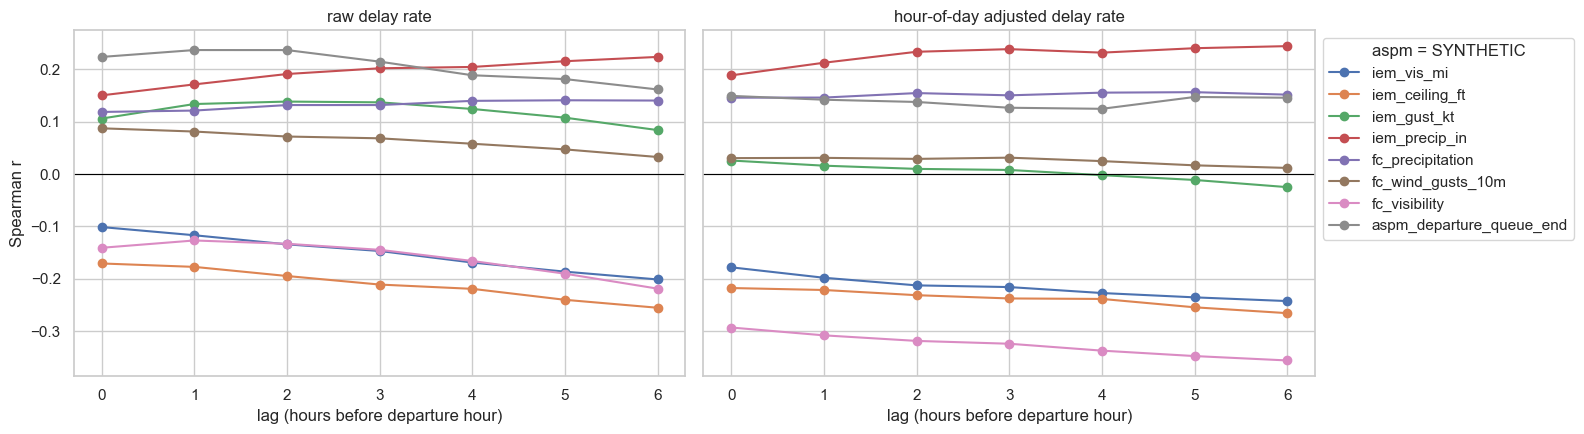

delay_rate                                                                                                                    delay_resid                                                            \
  iem_vis_mi iem_ceiling_ft iem_gust_kt iem_precip_in fc_precipitation fc_wind_gusts_10m fc_visibility aspm_departure_queue_end  iem_vis_mi iem_ceiling_ft iem_gust_kt iem_precip_in fc_precipitation   
0     -0.101         -0.171       0.106         0.150            0.119             0.087        -0.141                    0.224      -0.178         -0.218       0.026         0.189            0.146   
1     -0.117         -0.177       0.134         0.171            0.121             0.081        -0.127                    0.237      -0.198         -0.221       0.016         0.213            0.146   
2     -0.134         -0.195       0.138         0.191            0.132             0.072        -0.133                    0.237      -0.213         -0.231       0.010         0.234            0.155   
3     -0.147         -0.211       0.137         0.202            0.132             0.068        -0.145                    0.215      -0.216         -0.238       0.008         0.239            0.150   
4     -0.169         -0.219       0.124         0.205            0.140             0.058        -0.166                    0.189      -0.227         -0.239      -0.002         0.232            0.155   
5     -0.186         -0.240       0.108         0.216            0.141             0.047        -0.190                    0.181      -0.235         -0.254      -0.011         0.240            0.156   
6     -0.201         -0.255       0.084         0.224            0.140             0.033        -0.219                    0.162      -0.243         -0.266      -0.025         0.244            0.152   

                                                            
  fc_wind_gusts_10m fc_visibility aspm_departure_queue_end  
0             0.030        -0.293                    0.149  
1             0.031        -0.308                    0.142  
2             0.029        -0.319                    0.138  
3             0.031        -0.324                    0.127  
4             0.025        -0.337                    0.125  
5             0.017        -0.348                    0.147  
6             0.012        -0.356                    0.146

In [39]:
LAGGED = ["iem_vis_mi", "iem_ceiling_ft", "iem_gust_kt", "iem_precip_in", "fc_precipitation", "fc_wind_gusts_10m",
          "fc_visibility", "aspm_departure_queue_end"]
full = hourly.reindex(FULL)
lag_tabs = {}
for target in ["delay_rate", "delay_resid"]:
    t = pd.DataFrame(index=range(7), columns=LAGGED, dtype=float)
    for c in LAGGED:
        for k in range(7):
            x = pd.DataFrame({"y": full[target], "x": full[c].shift(k)}).loc[full.flights >= 5].dropna()
            t.loc[k, c] = stats.spearmanr(x.x, x.y)[0]
    lag_tabs[target] = t
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), sharey=True)
for ax, (target, t) in zip(axes, lag_tabs.items()):
    t.plot(ax=ax, marker="o", legend=False)
    ax.axhline(0, color="black", lw=0.8)
    ax.set(title={"delay_rate": "raw delay rate", "delay_resid": "hour-of-day adjusted delay rate"}[target],
           xlabel="lag (hours before departure hour)", ylabel="Spearman r")
axes[1].legend(bbox_to_anchor=(1, 1), title="aspm = SYNTHETIC")
plt.tight_layout(); plt.show()
pd.concat(lag_tabs, axis=1).round(3)

Weather from several hours **before** the departure hour correlates as strongly as, or more strongly than, same-hour weather. For observed precipitation, ceiling and visibility, and forecast visibility, the correlation grows from lag 0 to lag 6, with or without the hour adjustment. Delays build up after weather passes (ground delay programs, crew and aircraft out of position), so rolling 3–6 hour weather summaries should beat point-in-time values. Gust and wind signals vanish after the hour adjustment at every lag.

## 9. Forecasts vs observations

Forecast and observed values for the same hour after unit conversion. Visibility is capped at 10 mi (16,093 m), the most ASOS reports.

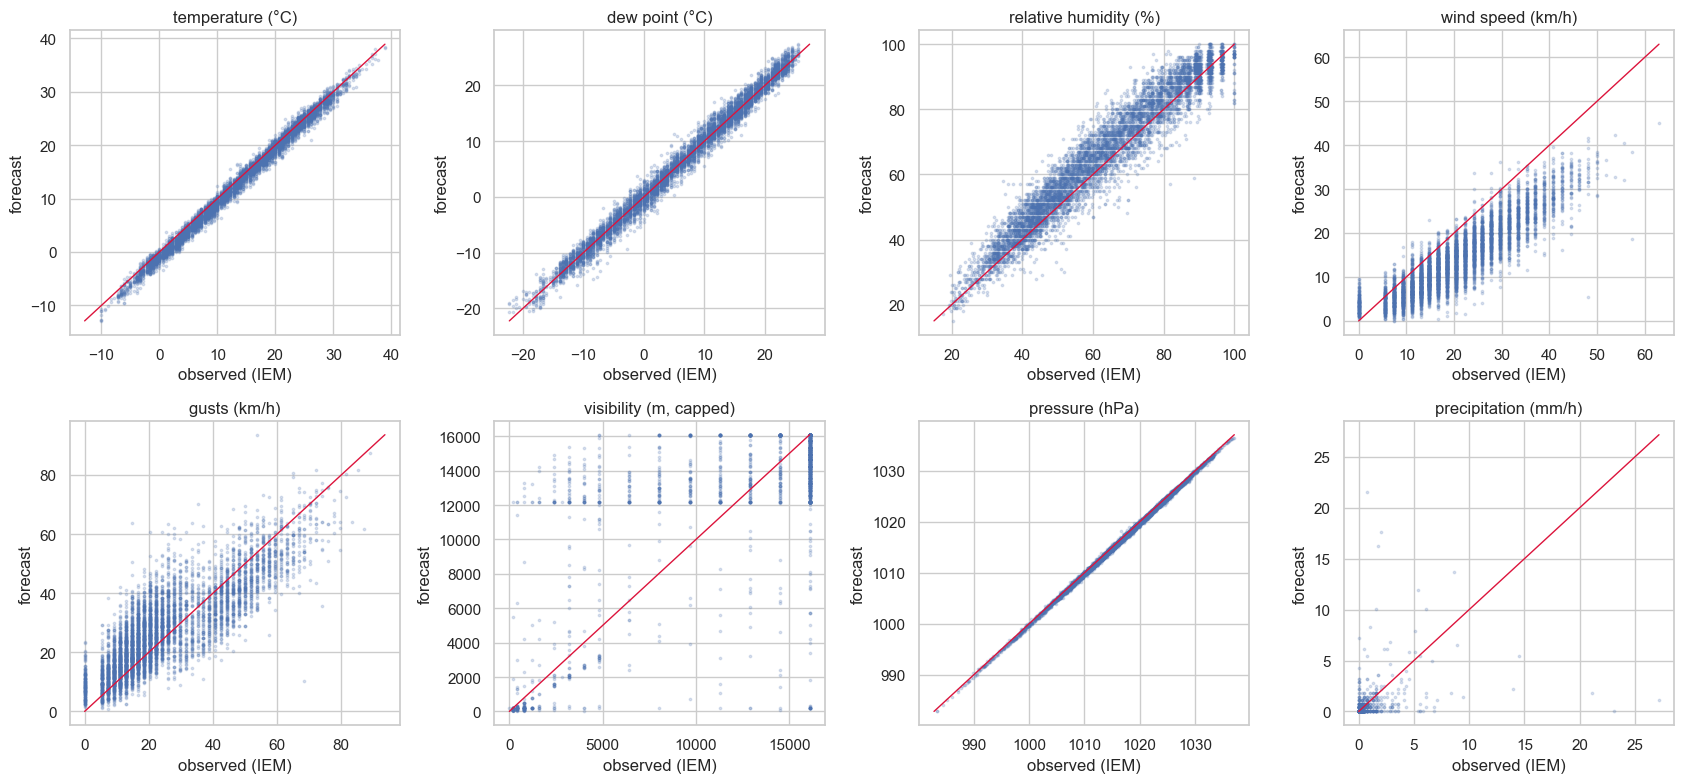

,hours,bias (fc - obs),MAE,pearson r
variable,,,,
temperature (°C),6515.0,-0.63,0.88,1.00
dew point (°C),6515.0,0.16,1.00,0.99
relative humidity (%),6515.0,3.06,4.79,0.96
wind speed (km/h),6514.0,-6.21,6.56,0.89
gusts (km/h),6514.0,2.51,7.01,0.84
"visibility (m, capped)",6514.0,29.92,726.69,0.80
pressure (hPa),6513.0,-0.21,0.24,1.00
precipitation (mm/h),6515.0,-0.02,0.10,0.37
wind direction (°),8700.0,NaN,17.00,NaN


In [40]:
pairs = {
    "temperature (°C)": ((hourly.iem_temp_f - 32) * 5 / 9, hourly.fc_temperature_2m),
    "dew point (°C)": ((hourly.iem_dewpt_f - 32) * 5 / 9, hourly.fc_dew_point_2m),
    "relative humidity (%)": (hourly.iem_relh, hourly.fc_relative_humidity_2m),
    "wind speed (km/h)": (hourly.iem_wind_kt * 1.852, hourly.fc_wind_speed_10m),
    "gusts (km/h)": (hourly.iem_gust_kt * 1.852, hourly.fc_wind_gusts_10m),
    "visibility (m, capped)": ((hourly.iem_vis_mi * 1609.34).clip(upper=16093), hourly.fc_visibility.clip(upper=16093)),
    "pressure (hPa)": (hourly.iem_mslp, hourly.fc_pressure_msl),
    "precipitation (mm/h)": (hourly.iem_precip_in * 25.4, hourly.fc_precipitation),
}
rows = []
fig, axes = plt.subplots(2, 4, figsize=(17, 8))
for ax, (name, (obs, fcst)) in zip(axes.flat, pairs.items()):
    x = pd.DataFrame({"obs": obs, "fc": fcst}).dropna()
    rows.append([name, len(x), (x.fc - x.obs).mean(), (x.fc - x.obs).abs().mean(), x.obs.corr(x.fc)])
    ax.scatter(x.obs, x.fc, s=3, alpha=0.2, color=BLUE)
    lim = [min(x.min()), max(x.max())]
    ax.plot(lim, lim, color="crimson", lw=1); ax.set(title=name, xlabel="observed (IEM)", ylabel="forecast")
plt.tight_layout(); plt.show()
fit = pd.DataFrame(rows, columns=["variable", "hours", "bias (fc - obs)", "MAE", "pearson r"]).set_index("variable")
dd = pd.DataFrame({"o": routine.drct, "f": fc_h.fc_wind_direction_10m}).dropna()
fit.loc["wind direction (°)"] = [len(dd), np.nan, ((dd.f - dd.o + 180) % 360 - 180).abs().mean(), np.nan]
fit.round(2)

Forecasts track observations closely for temperature, dew point and pressure (r ≥ 0.99), and well for humidity (0.96), wind (0.89, but the forecast is 6 km/h too low) and gusts (0.84). Visibility is moderate (0.80). Hourly **precipitation is poorly forecast** (r = 0.37), which is expected for convective timing. Wind direction is off by 17° on average.

In [41]:
pair_cols = [("iem_temp_f", "fc_temperature_2m"), ("iem_wind_kt", "fc_wind_speed_10m"), ("iem_gust_kt", "fc_wind_gusts_10m"),
             ("iem_vis_mi", "fc_visibility"), ("iem_precip_in", "fc_precipitation"), ("iem_relh", "fc_relative_humidity_2m"),
             ("iem_mslp", "fc_pressure_msl")]
s = spear.set_index("feature").spearman_r_hour_adj
pd.DataFrame([[o, s[o], f_, s[f_]] for o, f_ in pair_cols],
             columns=["observed", "r observed (hour-adj)", "forecast", "r forecast (hour-adj)"]).round(3)

,observed,r observed (hour-adj),forecast,r forecast (hour-adj)
0,iem_temp_f,0.048,fc_temperature_2m,0.049
1,iem_wind_kt,0.027,fc_wind_speed_10m,0.031
2,iem_gust_kt,0.026,fc_wind_gusts_10m,0.030
3,iem_vis_mi,-0.178,fc_visibility,-0.293
4,iem_precip_in,0.189,fc_precipitation,0.146
5,iem_relh,0.276,fc_relative_humidity_2m,0.294
6,iem_mslp,-0.166,fc_pressure_msl,-0.167


After the hour adjustment, forecast features carry about as much delay signal as observed ones, and forecast visibility carries more (−0.29 against −0.18). That's probably because observed visibility is capped at 10 miles while the forecast keeps resolving haze and moisture above it. A model built only on pre-departure forecasts loses little weather signal.

## 10. Leakage and feature readiness

In [42]:
POST = ["DepTime", "DepDelay", "DepDelayMinutes", "DepDel15", "DepartureDelayGroups", "TaxiOut", "WheelsOff", "WheelsOn",
        "TaxiIn", "ArrTime", "ArrDelay", "ArrDelayMinutes", "ArrDel15", "ArrivalDelayGroups", "Cancelled", "CancellationCode",
        "Diverted", "ActualElapsedTime", "AirTime", "CarrierDelay", "WeatherDelay", "NASDelay", "SecurityDelay",
        "LateAircraftDelay", "FirstDepTime", "TotalAddGTime", "LongestAddGTime"]
post = [c for c in flights.columns if c in POST or c.startswith("Div")]
print(f"BTS columns known only after departure ({len(post)}), excluded from features (DepDel15 is the label):")
print(", ".join(post))
print("\nFAA ASPM (synthetic) same-hour outcomes, excluded unless lagged:",
      "actual_departures, actual_arrivals, departure_queue_end, arrival_queue_end, avg_taxi_out_min, avg_taxi_in_min, "
      "avg_departure_delay_min, pct_ontime_departures, cancelled_departures, cancelled_arrivals")

BTS columns known only after departure (72), excluded from features (DepDel15 is the label):
DepTime, DepDelay, DepDelayMinutes, DepDel15, DepartureDelayGroups, TaxiOut, WheelsOff, WheelsOn, TaxiIn, ArrTime, ArrDelay, ArrDelayMinutes, ArrDel15, ArrivalDelayGroups, Cancelled, CancellationCode, Diverted, ActualElapsedTime, AirTime, CarrierDelay, WeatherDelay, NASDelay, SecurityDelay, LateAircraftDelay, FirstDepTime, TotalAddGTime, LongestAddGTime, DivAirportLandings, DivReachedDest, DivActualElapsedTime, DivArrDelay, DivDistance, Div1Airport, Div1AirportID, Div1AirportSeqID, Div1WheelsOn, Div1TotalGTime, Div1LongestGTime, Div1WheelsOff, Div1TailNum, Div2Airport, Div2AirportID, Div2AirportSeqID, Div2WheelsOn, Div2TotalGTime, Div2LongestGTime, Div2WheelsOff, Div2TailNum, Div3Airport, Div3AirportID, Div3AirportSeqID, Div3WheelsOn, Div3TotalGTime, Div3LongestGTime, Div3WheelsOff, Div3TailNum, Div4Airport, Div4AirportID, Div4AirportSeqID, Div4WheelsOn, Div4TotalGTime, Div4LongestGTime, Div4Wh

In [43]:
pd.DataFrame([
    ["BTS", "Reporting_Airline, Flight_Number, Dest, Distance, CRSElapsedTime", "schedule"],
    ["BTS", "dep hour / block, DayOfWeek, Month, holiday flags", "schedule calendar"],
    ["BTS", "Tail_Number -> aircraft type, max_seats, body, category", "aircraft assignment, usually known hours ahead"],
    ["BTS (derived)", "previous departure delay of same tail, JFK delay rate in prior hours", "only lags that end before the prediction time"],
    ["Open-Meteo", "forecast precipitation, gusts, visibility, temperature, weather_code", "forecasts issued before departure"],
    ["IEM", "latest observation before prediction time (lagged)", "only if predicting close to departure"],
    ["FAA ASPM (synthetic)", "scheduled departures/arrivals, runway config, AAR/ADR; lagged queues", "planned values or prior hours"],
], columns=["source", "candidate features", "known before departure because"])

,source,candidate features,known before departure because
0,BTS,"Reporting_Airline, Flight_Number, Dest, Distan...",schedule
1,BTS,"dep hour / block, DayOfWeek, Month, holiday flags",schedule calendar
2,BTS,"Tail_Number -> aircraft type, max_seats, body,...","aircraft assignment, usually known hours ahead"
3,BTS (derived),"previous departure delay of same tail, JFK del...",only lags that end before the prediction time
4,Open-Meteo,"forecast precipitation, gusts, visibility, tem...",forecasts issued before departure
5,IEM,latest observation before prediction time (lag...,only if predicting close to departure
6,FAA ASPM (synthetic),"scheduled departures/arrivals, runway config, ...",planned values or prior hours


In [44]:
split = pd.cut(done.Month, [0, 8, 10, 12], labels=["train Jan-Aug", "validate Sep-Oct", "test Nov-Dec"])
rate_by(done.assign(split=split), "split").round(1)

,flights,delayed,rate_pct
split,,,
train Jan-Aug,68255,14408,21.1
validate Sep-Oct,17265,2931,17.0
test Nov-Dec,16851,4205,25.0


Use a time-based split. Train on January–August, validate on September–October and test on November–December. Delay rates differ across these periods (21%, 17% and 25%), so check calibration on each and consider rolling-origin validation rather than a single split. A random split would leak storm days across sets, because flights in the same hour share outcomes.

## 11. Summary

**Strongest relationships**
- **Time of day** dominates: about 9% delayed in the morning against about 35% in the evening, and delays persist hour to hour (r = 0.70 at lag 1 h).
- **Knock-on delays:** late-arriving aircraft are the top cause (39% of cause minutes). A delayed previous JFK departure of the same aircraft doubles the delay risk (54% against 25%).
- **Weather (real):** thunderstorms (71% delayed), snow (38%), low visibility or ceiling (about 29%), and humidity and low cloud (hour-adjusted r ≈ 0.25–0.29). Weather from 3–6 hours earlier is at least as predictive as current weather. Pre-departure forecasts carry about as much signal as observations, so the leakage-safe forecast features are viable.
- **Destination:** after adjusting for airline and time, Boston (especially 14:00–17:00), Miami, Orlando, Chicago O'Hare, Atlanta, Dallas/Fort Worth and the Florida airports are 13–22% worse than expected. West Coast routes are about 20% better. Several effects are seasonal.
- **Aircraft size:** no meaningful independent relationship (r = −0.003); type differences mostly reflect airline and route.
- **Calendar:** Sundays, June–July and December are the worst periods; also a JetBlue effect.

**Data-quality items for preprocessing**
- Build IEM UTC from the METAR stamp. Keep the :51 and special reports, and deduplicate same-minute AUTO/SPECI pairs.
- Cap forecast visibility at 10 mi when combining with observations. Cap extreme delays (141 flights > 10 h).
- Aircraft lookup is missing about 20% of flights, mostly JetBlue's newest aircraft. The 787-8 seat count is unsourced, and seat values need verification.
- FAA ASPM is **synthetic**. Replace it with real ASPM data, or derive hourly congestion from BTS, before trusting any congestion feature.

**Open questions**
- Add inbound flights (`Dest == JFK`) to model delay propagation for every aircraft.
- Add destination-airport weather and FAA ground delay program data to explain the destination effects.
- Decide the prediction lead time (for example, 2 h or 24 h before departure). It determines which lagged observations and forecast runs are allowed.